In [ ]:
!nvidia-smi

Fri Oct  2 14:31:39 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   47C    P0             26W /   70W |     377MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
!git clone https://github.com/vishnubk/sgan.git
%cd sgan

!echo "=== Repository ==="
!ls -lah

!echo ""
!echo "=== Model files ==="
!find . -type f \( -name "*.h5" -o -name "*.pkl" \) -printf "%p  %k KB\n" | head -30

fatal: destination path 'sgan' already exists and is not an empty directory.
/content/sgan/sgan
=== Repository ===
total 1.3M
drwxr-xr-x 12 root root 4.0K Oct  2 14:26 .
drwxr-xr-x 13 root root 4.0K Oct  2 14:26 ..
drwxr-xr-x  2 root root 4.0K Oct  2 14:26 best_retrained_models
-rw-r--r--  1 root root 5.1K Oct  2 14:26 check_retrained_model_performance.py
-rw-r--r--  1 root root  51K Oct  2 14:26 classifiers.py
-rw-r--r--  1 root root 5.1K Oct  2 14:26 compute_sgan_score.py
-rw-r--r--  1 root root 1017 Oct  2 14:26 Dockerfile
-rw-r--r--  1 root root 5.8K Oct  2 14:26 extract_features_for_classification.py
-rw-r--r--  1 root root 3.4K Oct  2 14:26 extract_pfd_features.py
-rwxr-xr-x  1 root root  265 Oct  2 14:26 get_features.sh
-rwxr-xr-x  1 root root  250 Oct  2 14:26 get_pfd_features.sh
drwxr-xr-x  2 root root 4.0K Oct  2 14:26 GIFS
drwxr-xr-x  8 root root 4.0K Oct  2 14:26 .git
-rw-r--r--  1 root root  35K Oct  2 14:26 LICENSE
drwxr-xr-x  2 root root 4.0K Oct  2 14:26 __pycache__
-rw

In [ ]:
# We are already inside /content/sgan

print("=== Sample data ===")
!find sample_data -maxdepth 2 -type f | head -30

print("\n=== Validation data ===")
!find validation_data -maxdepth 2 -type f | head -30

print("\n=== Unlabelled data ===")
!find unlabelled_data -maxdepth 2 -type f | head -30

print("\n=== Test set ===")
!ls -lh test_set_relabelled_jan_2021.csv

print("\n=== SGAN scoring script dependencies ===")
!sed -n '1,180p' compute_sgan_score.py

=== Sample data ===
sample_data/training_labels.csv
sample_data/candidate_100_beam_04_segment_0_589.52ms_Cand.pfd.png
sample_data/candidate_27_beam_07_segment_0_1838.89ms_Cand.pfd.png
sample_data/J1732_lowlat_observation_freq_phase.npy
sample_data/candidate_100_beam_04_segment_0_589.52ms_Cand_time_phase.npy
sample_data/candidate_100_beam_04_segment_0_589.52ms_Cand_dm_curve.npy
sample_data/J1732_lowlat_observation_pulse_profile.npy
sample_data/candidate_27_beam_07_segment_0_1838.89ms_Cand_freq_phase.npy
sample_data/candidate_27_beam_07_segment_0_1838.89ms_Cand.pfd.ps
sample_data/J1732_lowlat_observation_time_phase.npy
sample_data/candidate_27_beam_07_segment_0_1838.89ms_Cand_pulse_profile.npy
sample_data/candidate_100_beam_04_segment_0_589.52ms_Cand.pfd
sample_data/candidate_100_beam_04_segment_0_589.52ms_Cand.pfd.bestprof
sample_data/J1722-3809_fold_freq_phase.npy
sample_data/J1722-3809_fold.ar2
sample_data/candidate_1_beam_01_segment_0_139.77ms_Cand_second.pfd
sample_data/J1732_lowlat

In [ ]:
# ============================================================
# STEP 2: VERIFY THE ORIGINAL SGAN PRETRAINED MODELS
# ============================================================

import os
import sys
import subprocess
import importlib.util

REPO = "/content/sgan"
os.chdir(REPO)

print("=" * 70)
print("SGAN REPRODUCTION TEST")
print("=" * 70)

# ------------------------------------------------------------
# 1. Check Python
# ------------------------------------------------------------
print("\n[1] Python")
print(sys.version)

# ------------------------------------------------------------
# 2. Check TensorFlow / Keras
# ------------------------------------------------------------
print("\n[2] Checking TensorFlow / Keras...")

try:
    import tensorflow as tf
    print("TensorFlow:", tf.__version__)
    print("Keras:", tf.keras.__version__ if hasattr(tf.keras, "__version__") else "bundled")
except Exception as e:
    print("TensorFlow import failed:", e)

# ------------------------------------------------------------
# 3. GPU
# ------------------------------------------------------------
print("\n[3] GPU")
try:
    gpus = tf.config.list_physical_devices("GPU")
    print("Available GPUs:", gpus)
except Exception as e:
    print("GPU check failed:", e)

# ------------------------------------------------------------
# 4. Verify all pretrained model files
# ------------------------------------------------------------
print("\n[4] PRETRAINED MODEL FILES")

model_files = {
    "frequency_phase":
        "semi_supervised_trained_models/"
        "freq_phase_best_discriminator_model_labelled_50814_unlabelled_265172_trial_4.h5",

    "time_phase":
        "semi_supervised_trained_models/"
        "time_phase_best_discriminator_model_labelled_50814_unlabelled_265172_trial_4.h5",

    "dm_curve":
        "semi_supervised_trained_models/"
        "dm_curve_best_discriminator_model_labelled_50814_unlabelled_265172_trial_4.h5",

    "pulse_profile":
        "semi_supervised_trained_models/"
        "pulse_profile_best_discriminator_model_labelled_50814_unlabelled_265172_trial_4.h5",

    "logistic":
        "semi_supervised_trained_models/"
        "logistic_regression_labelled_50814_unlabelled_265172_trial_4.pkl"
}

for name, path in model_files.items():
    full_path = os.path.join(REPO, path)

    if os.path.exists(full_path):
        size_mb = os.path.getsize(full_path) / (1024**2)
        print(f"  ✓ {name:20s} {size_mb:.2f} MB")
    else:
        print(f"  ✗ MISSING: {name}")

# ------------------------------------------------------------
# 5. Load pretrained models
# ------------------------------------------------------------
print("\n[5] Loading pretrained SGAN models...")

from tensorflow.keras.models import load_model
import pickle
import numpy as np
import pandas as pd
import time

loaded_models = {}

for name in ["frequency_phase", "time_phase", "dm_curve", "pulse_profile"]:

    path = os.path.join(REPO, model_files[name])

    print(f"\nLoading {name}...")
    start = time.time()

    loaded_models[name] = load_model(path, compile=False)

    elapsed = time.time() - start

    print(f"  ✓ Loaded in {elapsed:.2f} s")
    print(f"  Input shape : {loaded_models[name].input_shape}")
    print(f"  Output shape: {loaded_models[name].output_shape}")

# Logistic regression
logistic_path = os.path.join(REPO, model_files["logistic"])

with open(logistic_path, "rb") as f:
    logistic_model = pickle.load(f)

print("\n✓ Logistic regression model loaded.")
print("  Classes:", logistic_model.classes_)

# ------------------------------------------------------------
# 6. Find candidate files
# ------------------------------------------------------------
print("\n[6] Finding candidate files...")

sample_dir = os.path.join(REPO, "sample_data")
validation_dir = os.path.join(REPO, "validation_data")

def find_candidates(directory):
    files = []

    for filename in sorted(os.listdir(directory)):
        if filename.endswith(".pfd") or filename.endswith(".ar2"):
            files.append(os.path.join(directory, filename))

    return files

sample_candidates = find_candidates(sample_dir)
validation_candidates = find_candidates(validation_dir)

print(f"Sample candidates     : {len(sample_candidates)}")
print(f"Validation candidates : {len(validation_candidates)}")

print("\nSample candidates:")
for f in sample_candidates:
    print(" ", os.path.basename(f))

# ------------------------------------------------------------
# 7. Helper function for loading the four representations
# ------------------------------------------------------------

def load_candidate_features(candidate_file):

    base = candidate_file[:-4]

    dm_file = base + "_dm_curve.npy"
    pulse_file = base + "_pulse_profile.npy"
    freq_file = base + "_freq_phase.npy"
    time_file = base + "_time_phase.npy"

    required = [dm_file, pulse_file, freq_file, time_file]

    missing = [f for f in required if not os.path.exists(f)]

    if missing:
        raise FileNotFoundError(
            "Missing feature files:\n" +
            "\n".join(missing)
        )

    dm = np.load(dm_file)
    pulse = np.load(pulse_file)
    freq = np.load(freq_file)
    timep = np.load(time_file)

    # Match the preprocessing in the authors' scoring script
    dm = np.reshape(dm, (60, 1))
    pulse = np.reshape(pulse, (64, 1))
    freq = np.reshape(freq, (48, 48, 1))
    timep = np.reshape(timep, (48, 48, 1))

    # Normalize each candidate to [-1, +1]
    dm = np.interp(dm, (dm.min(), dm.max()), (-1, +1))
    pulse = np.interp(pulse, (pulse.min(), pulse.max()), (-1, +1))
    freq = np.interp(freq, (freq.min(), freq.max()), (-1, +1))
    timep = np.interp(timep, (timep.min(), timep.max()), (-1, +1))

    return freq, timep, dm, pulse


# ------------------------------------------------------------
# 8. Run SGAN inference
# ------------------------------------------------------------

def run_sgan(candidates):

    results = []

    print("\n[7] Running SGAN inference...")
    print("-" * 70)

    for i, candidate in enumerate(candidates):

        print(
            f"[{i+1}/{len(candidates)}] "
            f"{os.path.basename(candidate)}"
        )

        freq, timep, dm, pulse = load_candidate_features(candidate)

        # Add batch dimension
        freq = np.expand_dims(freq, axis=0)
        timep = np.expand_dims(timep, axis=0)
        dm = np.expand_dims(dm, axis=0)
        pulse = np.expand_dims(pulse, axis=0)

        start = time.time()

        # Four independent discriminator predictions
        pred_freq = loaded_models["frequency_phase"].predict(
            freq, verbose=0
        )

        pred_time = loaded_models["time_phase"].predict(
            timep, verbose=0
        )

        pred_dm = loaded_models["dm_curve"].predict(
            dm, verbose=0
        )

        pred_pulse = loaded_models["pulse_profile"].predict(
            pulse, verbose=0
        )

        # Convert softmax predictions into class labels
        pred_freq_class = np.argmax(
            np.rint(pred_freq), axis=1
        )

        pred_time_class = np.argmax(
            np.rint(pred_time), axis=1
        )

        pred_dm_class = np.argmax(
            np.rint(pred_dm), axis=1
        )

        pred_pulse_class = np.argmax(
            np.rint(pred_pulse), axis=1
        )

        # Stack the four predictions
        stacked = np.stack(
            [
                pred_freq_class,
                pred_time_class,
                pred_dm_class,
                pred_pulse_class
            ],
            axis=1
        )

        # Final SGAN logistic-regression score
        score = logistic_model.predict_proba(
            stacked
        )[:, 1][0]

        elapsed = time.time() - start

        results.append({
            "filename": os.path.basename(candidate),
            "freq_prediction": int(pred_freq_class[0]),
            "time_prediction": int(pred_time_class[0]),
            "dm_prediction": int(pred_dm_class[0]),
            "pulse_prediction": int(pred_pulse_class[0]),
            "sgan_score": float(score),
            "inference_time_sec": elapsed
        })

        print(
            f"    SGAN score = {score:.5f} | "
            f"time = {elapsed:.3f} s"
        )

    return pd.DataFrame(results)


# ------------------------------------------------------------
# 9. Run on supplied sample candidates
# ------------------------------------------------------------

sample_results = run_sgan(sample_candidates)

print("\n" + "=" * 70)
print("SGAN SAMPLE RESULTS")
print("=" * 70)

display(sample_results)

# ------------------------------------------------------------
# 10. Save results
# ------------------------------------------------------------

output_file = os.path.join(
    REPO,
    "our_sgan_sample_results.csv"
)

sample_results.to_csv(
    output_file,
    index=False
)

print("\nSaved:")
print(output_file)

# ------------------------------------------------------------
# 11. Basic statistics
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SUMMARY")
print("=" * 70)

print(
    "Number of candidates:",
    len(sample_results)
)

print(
    "Mean SGAN score:",
    sample_results["sgan_score"].mean()
)

print(
    "Minimum SGAN score:",
    sample_results["sgan_score"].min()
)

print(
    "Maximum SGAN score:",
    sample_results["sgan_score"].max()
)

print(
    "Mean inference time:",
    sample_results["inference_time_sec"].mean(),
    "seconds"
)

print("\n✓ ORIGINAL SGAN INFERENCE TEST COMPLETE")

SGAN REPRODUCTION TEST

[1] Python
3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]

[2] Checking TensorFlow / Keras...
TensorFlow: 2.20.0
Keras: 3.13.2

[3] GPU
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

[4] PRETRAINED MODEL FILES
  ✓ frequency_phase      24.24 MB
  ✓ time_phase           24.24 MB
  ✓ dm_curve             1.91 MB
  ✓ pulse_profile        2.38 MB
  ✓ logistic             0.00 MB

[5] Loading pretrained SGAN models...

Loading frequency_phase...
  ✓ Loaded in 0.09 s
  Input shape : (None, 48, 48, 1)
  Output shape: (None, 2)

Loading time_phase...
  ✓ Loaded in 0.09 s
  Input shape : (None, 48, 48, 1)
  Output shape: (None, 2)

Loading dm_curve...


/usr/local/lib/python3.13/dist-packages/keras/src/layers/activations/leaky_relu.py:41: UserWarning: Argument `alpha` is deprecated. Use `negative_slope` instead.
  warnings.warn(


  ✓ Loaded in 0.07 s
  Input shape : (None, 60, 1)
  Output shape: (None, 2)

Loading pulse_profile...
  ✓ Loaded in 0.07 s
  Input shape : (None, 64, 1)
  Output shape: (None, 2)

✓ Logistic regression model loaded.
  Classes: [0 1]

[6] Finding candidate files...
Sample candidates     : 5
Validation candidates : 5

Sample candidates:
  J1722-3809_fold.ar2
  J1732_lowlat_observation.ar2
  candidate_100_beam_04_segment_0_589.52ms_Cand.pfd
  candidate_1_beam_01_segment_0_139.77ms_Cand_second.pfd
  candidate_27_beam_07_segment_0_1838.89ms_Cand.pfd

[7] Running SGAN inference...
----------------------------------------------------------------------
[1/5] J1722-3809_fold.ar2


/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator LogisticRegression from version 0.22.1 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


    SGAN score = 0.00203 | time = 2.198 s
[2/5] J1732_lowlat_observation.ar2
    SGAN score = 0.00015 | time = 0.300 s
[3/5] candidate_100_beam_04_segment_0_589.52ms_Cand.pfd
    SGAN score = 0.00015 | time = 0.281 s
[4/5] candidate_1_beam_01_segment_0_139.77ms_Cand_second.pfd
    SGAN score = 0.99985 | time = 0.303 s
[5/5] candidate_27_beam_07_segment_0_1838.89ms_Cand.pfd
    SGAN score = 0.99985 | time = 0.294 s

SGAN SAMPLE RESULTS


,filename,freq_prediction,time_prediction,dm_prediction,pulse_prediction,sgan_score,inference_time_sec
0,J1722-3809_fold.ar2,0,0,1,0,0.002034,2.197830
1,J1732_lowlat_observation.ar2,0,0,0,0,0.000149,0.299538
2,candidate_100_beam_04_segment_0_589.52ms_Cand.pfd,0,0,0,0,0.000149,0.280826
3,candidate_1_beam_01_segment_0_139.77ms_Cand_se...,1,1,1,1,0.999847,0.303107
4,candidate_27_beam_07_segment_0_1838.89ms_Cand.pfd,1,1,1,1,0.999847,0.294033



Saved:
/content/sgan/our_sgan_sample_results.csv

SUMMARY
Number of candidates: 5
Mean SGAN score: 0.4004052344713559
Minimum SGAN score: 0.00014881285080560081
Maximum SGAN score: 0.999847225235009
Mean inference time: 0.6750666618347168 seconds

✓ ORIGINAL SGAN INFERENCE TEST COMPLETE


In [ ]:
# ============================================================
# STEP 3: VALIDATION OF THE PUBLISHED SGAN
# ============================================================

import os
import numpy as np
import pandas as pd
import time

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

REPO = "/content/sgan"
os.chdir(REPO)

VALIDATION_DIR = os.path.join(REPO, "validation_data")
LABEL_FILE = os.path.join(VALIDATION_DIR, "validation_labels.csv")

print("=" * 70)
print("STEP 3 — VALIDATING THE PUBLISHED SGAN")
print("=" * 70)

# ------------------------------------------------------------
# 1. Inspect validation labels
# ------------------------------------------------------------

print("\n[1] Reading validation labels...")

labels_df = pd.read_csv(LABEL_FILE)

print("Shape:", labels_df.shape)
print("\nColumns:")
print(labels_df.columns.tolist())

print("\nFirst rows:")
display(labels_df.head(10))

print("\nClass counts:")
print(labels_df.iloc[:, -1].value_counts())

# ------------------------------------------------------------
# 2. Identify label columns automatically
# ------------------------------------------------------------

print("\n[2] Identifying filename and label columns...")

filename_col = None
label_col = None

for col in labels_df.columns:

    lower = col.lower()

    if (
        "file" in lower
        or "name" in lower
        or "candidate" in lower
    ):
        filename_col = col

    if (
        "class" in lower
        or "label" in lower
        or "target" in lower
    ):
        label_col = col

print("Filename column:", filename_col)
print("Label column   :", label_col)

if filename_col is None:
    filename_col = labels_df.columns[0]

if label_col is None:
    label_col = labels_df.columns[-1]

# ------------------------------------------------------------
# 3. Normalize filenames
# ------------------------------------------------------------

def normalize_filename(x):

    x = str(x)

    # Remove possible directory information
    x = os.path.basename(x)

    return x


labels_df["normalized_filename"] = (
    labels_df[filename_col]
    .apply(normalize_filename)
)

# ------------------------------------------------------------
# 4. Find validation candidate files
# ------------------------------------------------------------

candidate_files = []

for filename in sorted(os.listdir(VALIDATION_DIR)):

    if filename.endswith(".pfd") or filename.endswith(".ar2"):

        candidate_files.append(
            os.path.join(VALIDATION_DIR, filename)
        )

print("\nNumber of validation candidates:", len(candidate_files))

# ------------------------------------------------------------
# 5. Match labels to candidate files
# ------------------------------------------------------------

label_lookup = dict(
    zip(
        labels_df["normalized_filename"],
        labels_df[label_col]
    )
)

matched_candidates = []
true_labels = []

unmatched = []

for candidate in candidate_files:

    basename = os.path.basename(candidate)

    if basename in label_lookup:

        matched_candidates.append(candidate)
        true_labels.append(label_lookup[basename])

    else:

        unmatched.append(basename)

print("\nMatched candidates:", len(matched_candidates))
print("Unmatched candidates:", len(unmatched))

if unmatched:

    print("\nUnmatched:")
    for x in unmatched:
        print(" ", x)

true_labels = np.array(true_labels)

print("\nTrue labels:")
print(true_labels)

# ------------------------------------------------------------
# 6. Function to reproduce SGAN prediction
# ------------------------------------------------------------

def load_candidate_features(candidate_file):

    base = candidate_file[:-4]

    dm_file = base + "_dm_curve.npy"
    pulse_file = base + "_pulse_profile.npy"
    freq_file = base + "_freq_phase.npy"
    time_file = base + "_time_phase.npy"

    required = [
        dm_file,
        pulse_file,
        freq_file,
        time_file
    ]

    missing = [
        f for f in required
        if not os.path.exists(f)
    ]

    if missing:

        raise FileNotFoundError(
            "Missing feature files:\n"
            + "\n".join(missing)
        )

    dm = np.load(dm_file)
    pulse = np.load(pulse_file)
    freq = np.load(freq_file)
    timep = np.load(time_file)

    dm = np.reshape(dm, (60, 1))
    pulse = np.reshape(pulse, (64, 1))
    freq = np.reshape(freq, (48, 48, 1))
    timep = np.reshape(timep, (48, 48, 1))

    # Same normalization used in the original script
    dm = np.interp(
        dm,
        (dm.min(), dm.max()),
        (-1, +1)
    )

    pulse = np.interp(
        pulse,
        (pulse.min(), pulse.max()),
        (-1, +1)
    )

    freq = np.interp(
        freq,
        (freq.min(), freq.max()),
        (-1, +1)
    )

    timep = np.interp(
        timep,
        (timep.min(), timep.max()),
        (-1, +1)
    )

    return freq, timep, dm, pulse


def predict_sgan(candidate):

    freq, timep, dm, pulse = (
        load_candidate_features(candidate)
    )

    freq = np.expand_dims(freq, 0)
    timep = np.expand_dims(timep, 0)
    dm = np.expand_dims(dm, 0)
    pulse = np.expand_dims(pulse, 0)

    # Four SGAN discriminators
    pred_freq = loaded_models[
        "frequency_phase"
    ].predict(freq, verbose=0)

    pred_time = loaded_models[
        "time_phase"
    ].predict(timep, verbose=0)

    pred_dm = loaded_models[
        "dm_curve"
    ].predict(dm, verbose=0)

    pred_pulse = loaded_models[
        "pulse_profile"
    ].predict(pulse, verbose=0)

    # Convert to binary class predictions
    pred_freq_class = np.argmax(
        np.rint(pred_freq),
        axis=1
    )[0]

    pred_time_class = np.argmax(
        np.rint(pred_time),
        axis=1
    )[0]

    pred_dm_class = np.argmax(
        np.rint(pred_dm),
        axis=1
    )[0]

    pred_pulse_class = np.argmax(
        np.rint(pred_pulse),
        axis=1
    )[0]

    stacked = np.array([[
        pred_freq_class,
        pred_time_class,
        pred_dm_class,
        pred_pulse_class
    ]])

    # Final SGAN probability
    score = logistic_model.predict_proba(
        stacked
    )[0, 1]

    return {
        "freq_prediction": int(pred_freq_class),
        "time_prediction": int(pred_time_class),
        "dm_prediction": int(pred_dm_class),
        "pulse_prediction": int(pred_pulse_class),
        "sgan_score": float(score)
    }


# ------------------------------------------------------------
# 7. Run on validation candidates
# ------------------------------------------------------------

print("\n[3] Running SGAN on validation set...")
print("-" * 70)

validation_results = []

for i, candidate in enumerate(matched_candidates):

    start = time.time()

    prediction = predict_sgan(candidate)

    elapsed = time.time() - start

    row = {
        "filename": os.path.basename(candidate),
        "true_label": true_labels[i],
        **prediction,
        "inference_time_sec": elapsed
    }

    validation_results.append(row)

    print(
        f"{i+1}/{len(matched_candidates)} "
        f"{row['filename']}"
        f" | true={row['true_label']}"
        f" | SGAN={row['sgan_score']:.6f}"
    )

results_df = pd.DataFrame(validation_results)

# ------------------------------------------------------------
# 8. Convert labels to numeric form
# ------------------------------------------------------------

print("\n[4] Inspecting labels...")

print(
    results_df[
        ["filename", "true_label", "sgan_score"]
    ]
)

print("\nUnique true labels:")
print(results_df["true_label"].unique())

# Convert common textual labels if necessary
def convert_label(x):

    if isinstance(x, str):

        x_lower = x.lower().strip()

        if x_lower in [
            "1",
            "true",
            "yes",
            "pulsar",
            "psr",
            "positive"
        ]:
            return 1

        if x_lower in [
            "0",
            "false",
            "no",
            "non-pulsar",
            "nonpulsar",
            "negative",
            "rfi"
        ]:
            return 0

    return int(x)


results_df["true_numeric"] = (
    results_df["true_label"]
    .apply(convert_label)
)

# SGAN threshold
# A score >= 0.5 is classified as pulsar
results_df["sgan_prediction"] = (
    results_df["sgan_score"] >= 0.5
).astype(int)

# ------------------------------------------------------------
# 9. Calculate metrics
# ------------------------------------------------------------

y_true = results_df["true_numeric"]
y_pred = results_df["sgan_prediction"]
y_score = results_df["sgan_score"]

print("\n" + "=" * 70)
print("SGAN VALIDATION METRICS")
print("=" * 70)

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(
    y_true,
    y_pred,
    zero_division=0
)
recall = recall_score(
    y_true,
    y_pred,
    zero_division=0
)
f1 = f1_score(
    y_true,
    y_pred,
    zero_division=0
)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")

if len(np.unique(y_true)) == 2:

    auc = roc_auc_score(
        y_true,
        y_score
    )

    print(f"ROC-AUC  : {auc:.4f}")

# ------------------------------------------------------------
# 10. Confusion matrix
# ------------------------------------------------------------

print("\nConfusion matrix:")
cm = confusion_matrix(
    y_true,
    y_pred
)

print(cm)

print("\nClassification report:")
print(
    classification_report(
        y_true,
        y_pred,
        digits=4,
        zero_division=0
    )
)

# ------------------------------------------------------------
# 11. Save validation results
# ------------------------------------------------------------

output_path = os.path.join(
    REPO,
    "sgan_validation_results.csv"
)

results_df.to_csv(
    output_path,
    index=False
)

print("\nSaved:")
print(output_path)

# ------------------------------------------------------------
# 12. Show final table
# ------------------------------------------------------------

print("\nFinal validation table:")
display(results_df)

print("\n" + "=" * 70)
print("STEP 3 COMPLETE")
print("=" * 70)

STEP 3 — VALIDATING THE PUBLISHED SGAN

[1] Reading validation labels...
Shape: (5, 2)

Columns:
['Filename', 'Classification']

First rows:


,Filename,Classification
0,candidate_154_beam_05_segment_0_499.06ms_Cand.pfd,1
1,candidate_200_beam_05_segment_0_8.15ms_Cand.pfd,0
2,candidate_23_beam_01_segment_0_1035.74ms_Cand.pfd,1
3,candidate_55_beam_10_segment_0_63.80ms_Cand.pfd,1
4,candidate_55_beam_11_segment_0_1996.38ms_Cand.pfd,0



Class counts:
Classification
1    3
0    2
Name: count, dtype: int64

[2] Identifying filename and label columns...
Filename column: Filename
Label column   : Classification

Number of validation candidates: 5

Matched candidates: 5
Unmatched candidates: 0

True labels:
[1 0 1 1 0]

[3] Running SGAN on validation set...
----------------------------------------------------------------------
1/5 candidate_154_beam_05_segment_0_499.06ms_Cand.pfd | true=1 | SGAN=0.999847
2/5 candidate_200_beam_05_segment_0_8.15ms_Cand.pfd | true=0 | SGAN=0.000149
3/5 candidate_23_beam_01_segment_0_1035.74ms_Cand.pfd | true=1 | SGAN=0.999493
4/5 candidate_55_beam_10_segment_0_63.80ms_Cand.pfd | true=1 | SGAN=0.999847
5/5 candidate_55_beam_11_segment_0_1996.38ms_Cand.pfd | true=0 | SGAN=0.000149

[4] Inspecting labels...
                                            filename  true_label  sgan_score
0  candidate_154_beam_05_segment_0_499.06ms_Cand.pfd           1    0.999847
1    candidate_200_beam_05_segment_

,filename,true_label,freq_prediction,time_prediction,dm_prediction,pulse_prediction,sgan_score,inference_time_sec,true_numeric,sgan_prediction
0,candidate_154_beam_05_segment_0_499.06ms_Cand.pfd,1,1,1,1,1,0.999847,0.313826,1,1
1,candidate_200_beam_05_segment_0_8.15ms_Cand.pfd,0,0,0,0,0,0.000149,0.312906,0,0
2,candidate_23_beam_01_segment_0_1035.74ms_Cand.pfd,1,1,1,1,0,0.999493,0.444751,1,1
3,candidate_55_beam_10_segment_0_63.80ms_Cand.pfd,1,1,1,1,1,0.999847,0.454695,1,1
4,candidate_55_beam_11_segment_0_1996.38ms_Cand.pfd,0,0,0,0,0,0.000149,0.471344,0,0



STEP 3 COMPLETE


In [ ]:
# ================================================================
# STEP 4 — VERIFY PUBLIC DATA AVAILABILITY
# ================================================================

import os
import glob
import subprocess
from pathlib import Path

REPO = Path("/content/sgan")

print("=" * 70)
print("STEP 4 — VERIFYING PUBLIC DATA AVAILABILITY")
print("=" * 70)

# ------------------------------------------------
# 1. Repository size
# ------------------------------------------------

def get_size(path):
    total = 0
    for root, dirs, files in os.walk(path):
        for f in files:
            try:
                total += os.path.getsize(os.path.join(root, f))
            except:
                pass
    return total

repo_size_gb = get_size(REPO) / 1024**3

print(f"\nRepository working-tree size: {repo_size_gb:.2f} GB")


# ------------------------------------------------
# 2. List important files
# ------------------------------------------------

print("\n" + "=" * 70)
print("[1] IMPORTANT REPOSITORY FILES")
print("=" * 70)

important_patterns = [
    "*.md",
    "*.sh",
    "*.csv",
    "*.txt",
    "*.py"
]

for pattern in important_patterns:

    files = sorted(REPO.rglob(pattern))

    print(f"\n{pattern}: {len(files)} files")

    for f in files[:30]:
        rel = f.relative_to(REPO)
        size_mb = f.stat().st_size / 1024**2
        print(f"  {rel}   ({size_mb:.2f} MB)")

    if len(files) > 30:
        print(f"  ... {len(files)-30} more")


# ------------------------------------------------
# 3. Search README for dataset/download information
# ------------------------------------------------

print("\n" + "=" * 70)
print("[2] SEARCHING README / SCRIPTS FOR DATASET INFORMATION")
print("=" * 70)

search_terms = [
    "download",
    "dataset",
    "ftp",
    "http",
    "unlabelled",
    "labelled",
    "3 GB",
    "272 GB",
    "features"
]

text_files = (
    list(REPO.glob("*.md")) +
    list(REPO.glob("*.txt")) +
    list(REPO.glob("*.sh"))
)

for file in text_files:

    try:
        text = file.read_text(errors="ignore")
    except:
        continue

    matches = []

    for i, line in enumerate(text.splitlines(), 1):

        low = line.lower()

        if any(term.lower() in low for term in search_terms):
            matches.append((i, line.strip()))

    if matches:

        print(f"\n--- {file.relative_to(REPO)} ---")

        for i, line in matches[:80]:
            print(f"{i:4d}: {line}")


# ------------------------------------------------
# 4. Count candidate representations already present
# ------------------------------------------------

print("\n" + "=" * 70)
print("[3] CANDIDATE DATA COUNTS")
print("=" * 70)

representations = [
    "_freq_phase.npy",
    "_time_phase.npy",
    "_dm_curve.npy",
    "_pulse_profile.npy"
]

for rep in representations:

    files = list(REPO.rglob(f"*{rep}"))

    print(f"{rep:25s}: {len(files):8d}")


# ------------------------------------------------
# 5. Count labelled/unlabelled files by directory
# ------------------------------------------------

print("\n" + "=" * 70)
print("[4] DIRECTORY CONTENT SUMMARY")
print("=" * 70)

for dirname in [
    "sample_data",
    "validation_data",
    "unlabelled_data",
    "supervised_trained_models",
    "semi_supervised_trained_models",
    "best_retrained_models"
]:

    path = REPO / dirname

    if not path.exists():
        print(f"\n{dirname}: NOT FOUND")
        continue

    all_files = [
        f for f in path.rglob("*")
        if f.is_file()
    ]

    print(f"\n{dirname}/")
    print(f"  Files: {len(all_files)}")

    # Show extensions
    extensions = {}

    for f in all_files:
        ext = f.suffix.lower() or "[no extension]"
        extensions[ext] = extensions.get(ext, 0) + 1

    for ext, count in sorted(
        extensions.items(),
        key=lambda x: x[1],
        reverse=True
    )[:15]:

        print(f"  {ext:15s}: {count}")


# ------------------------------------------------
# 6. Check Git remote
# ------------------------------------------------

print("\n" + "=" * 70)
print("[5] GIT REMOTE")
print("=" * 70)

try:

    remote = subprocess.check_output(
        ["git", "-C", str(REPO), "remote", "-v"],
        text=True
    )

    print(remote)

except Exception as e:

    print("Could not read git remote:", e)


# ------------------------------------------------
# 7. Final decision information
# ------------------------------------------------

print("\n" + "=" * 70)
print("STEP 4 COMPLETE")
print("=" * 70)

print("""
IMPORTANT:
We are NOT downloading the large dataset yet.

The output above will tell us:
1. Where the full labelled dataset is hosted.
2. Whether the download is genuinely public.
3. Whether feature files are already provided.
4. Whether we can reproduce the experiment without contacting authors.
""")

STEP 4 — VERIFYING PUBLIC DATA AVAILABILITY

Repository working-tree size: 1.26 GB

[1] IMPORTANT REPOSITORY FILES

*.md: 2 files
  README.md   (0.00 MB)
  sgan/README.md   (0.00 MB)

*.sh: 4 files
  get_features.sh   (0.00 MB)
  get_pfd_features.sh   (0.00 MB)
  sgan/get_features.sh   (0.00 MB)
  sgan/get_pfd_features.sh   (0.00 MB)

*.csv: 10 files
  our_sgan_sample_results.csv   (0.00 MB)
  sample_data/training_labels.csv   (0.00 MB)
  sgan/sample_data/training_labels.csv   (0.00 MB)
  sgan/sgan_ai_score.csv   (0.00 MB)
  sgan/test_set_relabelled_jan_2021.csv   (1.05 MB)
  sgan/validation_data/validation_labels.csv   (0.00 MB)
  sgan_ai_score.csv   (0.00 MB)
  sgan_validation_results.csv   (0.00 MB)
  test_set_relabelled_jan_2021.csv   (1.05 MB)
  validation_data/validation_labels.csv   (0.00 MB)

*.txt: 6 files
  sgan/training_logs/model_performance_sgan_dm_curve.txt   (0.03 MB)
  sgan/training_logs/model_performance_sgan_freq_phase.txt   (0.01 MB)
  sgan/training_logs/model_perfor

In [ ]:
# ================================================================
# STEP 5 — TEST PUBLIC DATA DOWNLOAD
# ================================================================

import os
import re
import subprocess
from pathlib import Path

REPO = Path("/content/sgan")

print("=" * 70)
print("STEP 5 — TESTING PUBLIC DATA ACCESS")
print("=" * 70)

# ------------------------------------------------
# 1. Read README
# ------------------------------------------------

readme = (REPO / "README.md").read_text(errors="ignore")

print("\n[1] DATASET LINKS FOUND IN README")
print("-" * 70)

for line in readme.splitlines():

    if "ftp.mpifr" in line.lower():
        print(line)


# ------------------------------------------------
# 2. Extract FTP URLs
# ------------------------------------------------

urls = re.findall(
    r'ftp\.mpifr-bonn\.mpg\.de:\S+',
    readme
)

print("\nExtracted FTP paths:")

for url in urls:
    print(" ", url)


# ------------------------------------------------
# 3. Test FTP connectivity
# ------------------------------------------------

print("\n" + "=" * 70)
print("[2] TESTING FTP SERVER")
print("=" * 70)

try:

    result = subprocess.run(
        [
            "curl",
            "-I",
            "--connect-timeout", "15",
            "--max-time", "30",
            "ftp://ftp.mpifr-bonn.mpg.de/"
        ],
        capture_output=True,
        text=True
    )

    print("Return code:", result.returncode)

    if result.stdout:
        print("\nSTDOUT:")
        print(result.stdout[:4000])

    if result.stderr:
        print("\nSTDERR:")
        print(result.stderr[:4000])

except Exception as e:

    print("FTP test failed:", e)


# ------------------------------------------------
# 4. Test HTTP/HTTPS alternatives
# ------------------------------------------------

print("\n" + "=" * 70)
print("[3] TESTING HTTPS ACCESS")
print("=" * 70)

test_urls = [
    "https://ftp.mpifr-bonn.mpg.de/",
    "http://ftp.mpifr-bonn.mpg.de/"
]

for url in test_urls:

    print("\nTesting:", url)

    try:

        result = subprocess.run(
            [
                "curl",
                "-I",
                "--connect-timeout", "15",
                "--max-time", "30",
                url
            ],
            capture_output=True,
            text=True
        )

        print("Return code:", result.returncode)

        if result.stdout:
            print(result.stdout[:2000])

        if result.stderr:
            print(result.stderr[:1000])

    except Exception as e:

        print("Failed:", e)


# ------------------------------------------------
# 5. Check whether dataset already exists locally
# ------------------------------------------------

print("\n" + "=" * 70)
print("[4] CHECKING FOR DATASET ALREADY PRESENT")
print("=" * 70)

possible_files = [
    "downsampled_normalised_data.tar.gz",
    "labelled_candidates_sgan_paper_jan_2021.csv",
    "sgan_lowlat_raw_dataset.tar.gz"
]

search_roots = [
    Path("/content"),
    Path("/content/sgan")
]

for filename in possible_files:

    found = []

    for root in search_roots:

        try:
            found.extend(root.rglob(filename))
        except:
            pass

    print(f"\n{filename}")

    if found:

        for f in found:
            print("  FOUND:", f)

    else:

        print("  Not present locally")


print("\n" + "=" * 70)
print("STEP 5 COMPLETE")
print("=" * 70)

print("""
DO NOT DOWNLOAD THE 3-GB ARCHIVE YET.

We first need to confirm that the public MPIfR endpoint
is accessible from Colab.

If it is accessible:
    → download only the 3-GB processed dataset + labels.

If it is inaccessible:
    → we investigate an official mirror/public alternative.

We will NOT use private or author-only data.
""")

STEP 5 — TESTING PUBLIC DATA ACCESS

[1] DATASET LINKS FOUND IN README
----------------------------------------------------------------------
Raw Data (272 GB): ftp.mpifr-bonn.mpg.de:outgoing/vishnu/sgan_data/sgan_lowlat_raw_dataset.tar.gz
File Labels Full Dataset: ftp.mpifr-bonn.mpg.de:outgoing/vishnu/sgan_data/labelled_candidates_sgan_paper_jan_2021.csv
Test Set Labels: ftp.mpifr-bonn.mpg.de:outgoing/vishnu/sgan_data/test_set_relabelled_jan_2021.csv
Downsampled & Normalised Files (3 GB): ftp.mpifr-bonn.mpg.de:outgoing/vishnu/sgan_data/downsampled_normalised_data.tar.gz

Extracted FTP paths:
  ftp.mpifr-bonn.mpg.de:outgoing/vishnu/sgan_data/sgan_lowlat_raw_dataset.tar.gz
  ftp.mpifr-bonn.mpg.de:outgoing/vishnu/sgan_data/labelled_candidates_sgan_paper_jan_2021.csv
  ftp.mpifr-bonn.mpg.de:outgoing/vishnu/sgan_data/test_set_relabelled_jan_2021.csv
  ftp.mpifr-bonn.mpg.de:outgoing/vishnu/sgan_data/downsampled_normalised_data.tar.gz

[2] TESTING FTP SERVER
Return code: 0

STDERR:
  % Total

In [ ]:
# ================================================================
# STEP 6 — VERIFY EXACT DATASET FILES
# ================================================================

import subprocess
import re

BASE = "https://ftp.mpifr-bonn.mpg.de/outgoing/vishnu/sgan_data/"

FILES = [
    "downsampled_normalised_data.tar.gz",
    "labelled_candidates_sgan_paper_jan_2021.csv",
    "test_set_relabelled_jan_2021.csv",
]

print("=" * 70)
print("STEP 6 — VERIFYING EXACT PUBLIC DATASET FILES")
print("=" * 70)

for filename in FILES:

    url = BASE + filename

    print("\n" + "-" * 70)
    print("FILE:", filename)
    print("URL :", url)
    print("-" * 70)

    try:

        result = subprocess.run(
            [
                "curl",
                "-I",
                "-L",
                "--connect-timeout", "20",
                "--max-time", "40",
                url
            ],
            capture_output=True,
            text=True
        )

        print("Return code:", result.returncode)

        headers = result.stdout

        # Print useful headers only
        for line in headers.splitlines():

            low = line.lower()

            if any(key in low for key in [
                "http/",
                "content-length",
                "content-type",
                "accept-ranges",
                "last-modified",
                "etag",
                "location"
            ]):

                print(line)

        if result.stderr:
            print("\nSTDERR:")
            print(result.stderr[-1500:])

    except Exception as e:

        print("ERROR:", e)


print("\n" + "=" * 70)
print("STEP 6 COMPLETE")
print("=" * 70)

print("""
No dataset has been downloaded by this test.

We are checking:
• exact file availability
• file size
• HTTPS response
• whether range requests are supported

If everything is correct, we will download ONLY:
1. downsampled_normalised_data.tar.gz
2. labelled_candidates_sgan_paper_jan_2021.csv
3. test_set_relabelled_jan_2021.csv

We will NOT download the 272 GB raw dataset.
""")

STEP 6 — VERIFYING EXACT PUBLIC DATASET FILES

----------------------------------------------------------------------
FILE: downsampled_normalised_data.tar.gz
URL : https://ftp.mpifr-bonn.mpg.de/outgoing/vishnu/sgan_data/downsampled_normalised_data.tar.gz
----------------------------------------------------------------------
Return code: 0
HTTP/1.1 200 OK
Last-Modified: Sun, 30 Apr 2023 23:33:36 GMT
ETag: "18de86dc-5fa9622a3ecb7"
Accept-Ranges: bytes
Content-Length: 417236700
Content-Type: application/x-gzip

STDERR:
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed

  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
  0  397M    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0


----------------------------------------------------------------------
FILE: la

In [ ]:
# ================================================================
# STEP 7 — DOWNLOAD PUBLIC SGAN DATASET
# ================================================================

import os
import subprocess
from pathlib import Path

DATA_DIR = Path("/content/sgan_dataset")
DATA_DIR.mkdir(exist_ok=True)

BASE = "https://ftp.mpifr-bonn.mpg.de/outgoing/vishnu/sgan_data/"

FILES = {
    "downsampled_normalised_data.tar.gz":
        BASE + "downsampled_normalised_data.tar.gz",

    "labelled_candidates_sgan_paper_jan_2021.csv":
        BASE + "labelled_candidates_sgan_paper_jan_2021.csv",

    "test_set_relabelled_jan_2021.csv":
        BASE + "test_set_relabelled_jan_2021.csv",
}


print("=" * 70)
print("STEP 7 — DOWNLOADING PUBLIC SGAN DATASET")
print("=" * 70)

for filename, url in FILES.items():

    output = DATA_DIR / filename

    print("\n" + "-" * 70)
    print("Downloading:", filename)
    print("Destination:", output)
    print("-" * 70)

    command = [
        "wget",
        "-c",
        "--show-progress",
        "--tries=5",
        "--timeout=60",
        url,
        "-O",
        str(output)
    ]

    result = subprocess.run(command)

    if result.returncode != 0:
        raise RuntimeError(
            f"Download failed for {filename}"
        )

    size_mb = output.stat().st_size / 1024**2

    print(
        f"\nDownloaded successfully: "
        f"{size_mb:.2f} MB"
    )


# ------------------------------------------------
# Final verification
# ------------------------------------------------

print("\n" + "=" * 70)
print("DOWNLOADED FILES")
print("=" * 70)

for file in DATA_DIR.iterdir():

    if file.is_file():

        size_mb = file.stat().st_size / 1024**2

        print(
            f"{file.name:55s} "
            f"{size_mb:10.2f} MB"
        )


print("\n" + "=" * 70)
print("STEP 7 COMPLETE")
print("=" * 70)

STEP 7 — DOWNLOADING PUBLIC SGAN DATASET

----------------------------------------------------------------------
Downloading: downsampled_normalised_data.tar.gz
Destination: /content/sgan_dataset/downsampled_normalised_data.tar.gz
----------------------------------------------------------------------

Downloaded successfully: 397.91 MB

----------------------------------------------------------------------
Downloading: labelled_candidates_sgan_paper_jan_2021.csv
Destination: /content/sgan_dataset/labelled_candidates_sgan_paper_jan_2021.csv
----------------------------------------------------------------------

Downloaded successfully: 4.20 MB

----------------------------------------------------------------------
Downloading: test_set_relabelled_jan_2021.csv
Destination: /content/sgan_dataset/test_set_relabelled_jan_2021.csv
----------------------------------------------------------------------

Downloaded successfully: 1.05 MB

DOWNLOADED FILES
downsampled_normalised_data.tar.gz      

In [ ]:
# ================================================================
# STEP 8 — FRESH DATASET CHECK + INSPECTION
# ================================================================

import os
import tarfile
import gzip
import pandas as pd
import numpy as np
from pathlib import Path
from collections import Counter
import subprocess

DATA_DIR = Path("/content/sgan_dataset")

ARCHIVE = DATA_DIR / "downsampled_normalised_data.tar.gz"
LABEL_FILE = DATA_DIR / "labelled_candidates_sgan_paper_jan_2021.csv"
TEST_FILE = DATA_DIR / "test_set_relabelled_jan_2021.csv"

ARCHIVE_URL = (
    "https://ftp.mpifr-bonn.mpg.de/"
    "outgoing/vishnu/sgan_data/"
    "downsampled_normalised_data.tar.gz"
)

EXPECTED_ARCHIVE_SIZE = 417236700

print("=" * 70)
print("STEP 8 — FRESH DATASET CHECK")
print("=" * 70)


# ================================================================
# 1. Check files
# ================================================================

print("\n" + "=" * 70)
print("[1] CHECKING DOWNLOADED FILES")
print("=" * 70)

for file in [ARCHIVE, LABEL_FILE, TEST_FILE]:

    if file.exists():

        size = file.stat().st_size

        print(
            f"✓ {file.name:55s}"
            f"{size / 1024**2:10.2f} MB"
        )

    else:

        print(f"✗ MISSING: {file.name}")


if not ARCHIVE.exists():
    raise FileNotFoundError(
        "Dataset archive is missing."
    )

if not LABEL_FILE.exists():
    raise FileNotFoundError(
        "Full label CSV is missing."
    )

if not TEST_FILE.exists():
    raise FileNotFoundError(
        "Test label CSV is missing."
    )


# ================================================================
# 2. Check archive size
# ================================================================

print("\n" + "=" * 70)
print("[2] CHECKING ARCHIVE SIZE")
print("=" * 70)

archive_size = ARCHIVE.stat().st_size

print(
    "Local size:",
    f"{archive_size:,} bytes",
    f"({archive_size / 1024**2:.2f} MiB)"
)

print(
    "Expected size:",
    f"{EXPECTED_ARCHIVE_SIZE:,} bytes",
    f"({EXPECTED_ARCHIVE_SIZE / 1024**2:.2f} MiB)"
)

if archive_size == EXPECTED_ARCHIVE_SIZE:

    print("✓ Archive size matches.")

else:

    print("⚠ Archive size does not match.")


# ================================================================
# 3. GZIP integrity
# ================================================================

print("\n" + "=" * 70)
print("[3] TESTING GZIP INTEGRITY")
print("=" * 70)

gzip_test = subprocess.run(
    ["gzip", "-t", str(ARCHIVE)],
    capture_output=True,
    text=True
)

if gzip_test.returncode == 0:

    print("✓ GZIP integrity check PASSED.")

else:

    print("✗ GZIP integrity check FAILED.")

    if gzip_test.stderr:
        print(gzip_test.stderr)

    print("\nAttempting a CLEAN redownload...")

    # Remove corrupt archive
    ARCHIVE.unlink()

    # Fresh download
    download = subprocess.run(
        [
            "wget",
            "--show-progress",
            "--tries=5",
            "--timeout=120",
            ARCHIVE_URL,
            "-O",
            str(ARCHIVE)
        ]
    )

    if download.returncode != 0:
        raise RuntimeError(
            "Fresh dataset download failed."
        )

    # Check size again
    new_size = ARCHIVE.stat().st_size

    print(
        "\nFresh archive size:",
        f"{new_size:,} bytes"
    )

    # Check gzip again
    gzip_test = subprocess.run(
        ["gzip", "-t", str(ARCHIVE)],
        capture_output=True,
        text=True
    )

    if gzip_test.returncode != 0:

        print(
            "\n✗ Fresh archive STILL fails gzip integrity."
        )

        print(gzip_test.stderr)

        raise RuntimeError(
            "Public archive appears to be truncated/corrupt. "
            "STOP here before extraction."
        )

    else:

        print(
            "\n✓ Fresh archive passed gzip integrity."
        )


# ================================================================
# 4. Inspect TAR archive
# ================================================================

print("\n" + "=" * 70)
print("[4] INSPECTING TAR ARCHIVE")
print("=" * 70)

with tarfile.open(ARCHIVE, "r:gz") as tar:

    members = tar.getmembers()

    files = [
        m for m in members
        if m.isfile()
    ]

    print(
        "Archive entries:",
        len(members)
    )

    print(
        "Files:",
        len(files)
    )

    total_size = sum(
        m.size for m in files
    )

    print(
        "Uncompressed size:",
        f"{total_size / 1024**3:.2f} GB"
    )

    print("\nFirst 30 files:")

    for m in files[:30]:

        print(
            f"{m.name:90s}"
            f"{m.size / 1024:.1f} KB"
        )


# ================================================================
# 5. Count feature representations
# ================================================================

print("\n" + "=" * 70)
print("[5] FEATURE REPRESENTATIONS")
print("=" * 70)

representation_patterns = {
    "freq_phase": "_freq_phase.npy",
    "time_phase": "_time_phase.npy",
    "dm_curve": "_dm_curve.npy",
    "pulse_profile": "_pulse_profile.npy",
}

representation_counts = {}

for name, pattern in representation_patterns.items():

    count = sum(
        1
        for m in files
        if Path(m.name).name.endswith(pattern)
    )

    representation_counts[name] = count

    print(
        f"{name:20s}: {count:,}"
    )


# ================================================================
# 6. Inspect full labels
# ================================================================

print("\n" + "=" * 70)
print("[6] FULL LABEL DATASET")
print("=" * 70)

labels = pd.read_csv(LABEL_FILE)

print(
    "Shape:",
    labels.shape
)

print(
    "\nColumns:",
    labels.columns.tolist()
)

print("\nFirst 10 rows:")

display(labels.head(10))

print("\nClass counts:")

for col in labels.columns:

    unique = labels[col].nunique()

    if unique <= 10:

        print(
            f"\n{col}:"
        )

        print(
            labels[col].value_counts(
                dropna=False
            )
        )


# ================================================================
# 7. Inspect test labels
# ================================================================

print("\n" + "=" * 70)
print("[7] TEST LABEL DATASET")
print("=" * 70)

test_labels = pd.read_csv(TEST_FILE)

print(
    "Shape:",
    test_labels.shape
)

print(
    "\nColumns:",
    test_labels.columns.tolist()
)

display(test_labels.head(10))

print("\nClass counts:")

for col in test_labels.columns:

    if test_labels[col].nunique() <= 10:

        print(
            f"\n{col}:"
        )

        print(
            test_labels[col].value_counts(
                dropna=False
            )
        )


# ================================================================
# 8. Identify filename columns
# ================================================================

print("\n" + "=" * 70)
print("[8] IDENTIFYING FILENAME COLUMNS")
print("=" * 70)

def find_filename_columns(df):

    candidates = []

    for col in df.columns:

        name = str(col).lower()

        if any(
            keyword in name
            for keyword in [
                "file",
                "filename",
                "candidate",
                "pfd"
            ]
        ):

            candidates.append(col)

    return candidates


label_filename_cols = find_filename_columns(
    labels
)

test_filename_cols = find_filename_columns(
    test_labels
)

print(
    "Full dataset filename candidates:",
    label_filename_cols
)

print(
    "Test dataset filename candidates:",
    test_filename_cols
)


# ================================================================
# 9. Inspect representative arrays
# ================================================================

print("\n" + "=" * 70)
print("[9] INSPECTING REPRESENTATIVE ARRAYS")
print("=" * 70)

inspection_dir = DATA_DIR / "inspection"
inspection_dir.mkdir(exist_ok=True)

selected = []

for m in files:

    name = Path(m.name).name

    if any(
        name.endswith(pattern)
        for pattern in representation_patterns.values()
    ):

        selected.append(m)

    if len(selected) >= 8:
        break


with tarfile.open(ARCHIVE, "r:gz") as tar:

    for m in selected:

        print("\nFile:")
        print(" ", m.name)

        extracted = tar.extractfile(m)

        if extracted is None:

            print("  Could not extract.")
            continue

        output_file = (
            inspection_dir /
            Path(m.name).name
        )

        with open(output_file, "wb") as f:

            f.write(
                extracted.read()
            )

        arr = np.load(output_file)

        print(
            "  Shape :",
            arr.shape
        )

        print(
            "  Dtype :",
            arr.dtype
        )

        print(
            "  Min   :",
            np.min(arr)
        )

        print(
            "  Max   :",
            np.max(arr)
        )

        print(
            "  Mean  :",
            np.mean(arr)
        )

        print(
            "  Std   :",
            np.std(arr)
        )


print("\n" + "=" * 70)
print("STEP 8 COMPLETE")
print("=" * 70)

print("""
If this step completes successfully, we have verified:

✓ Dataset integrity
✓ Archive structure
✓ Number of feature files
✓ Four feature representations
✓ Full labels
✓ Test labels
✓ Filename structure
✓ Array shapes and normalization

NO MODEL TRAINING HAS BEEN DONE YET.
""")

STEP 8 — FRESH DATASET CHECK

[1] CHECKING DOWNLOADED FILES
✓ downsampled_normalised_data.tar.gz                         397.91 MB
✓ labelled_candidates_sgan_paper_jan_2021.csv                  4.20 MB
✓ test_set_relabelled_jan_2021.csv                             1.05 MB

[2] CHECKING ARCHIVE SIZE
Local size: 417,236,700 bytes (397.91 MiB)
Expected size: 417,236,700 bytes (397.91 MiB)
✓ Archive size matches.

[3] TESTING GZIP INTEGRITY
✗ GZIP integrity check FAILED.

gzip: /content/sgan_dataset/downsampled_normalised_data.tar.gz: unexpected end of file


Attempting a CLEAN redownload...

Fresh archive size: 417,236,700 bytes

✗ Fresh archive STILL fails gzip integrity.

gzip: /content/sgan_dataset/downsampled_normalised_data.tar.gz: unexpected end of file



RuntimeError: Public archive appears to be truncated/corrupt. STOP here before extraction.

In [ ]:
# ================================================================
# STEP 9 — COMPLETE PUBLIC CANDIDATE INVENTORY
# ================================================================

import os
import numpy as np
import pandas as pd
from pathlib import Path

REPO = Path("/content/sgan")

print("=" * 70)
print("STEP 9 — PUBLIC CANDIDATE INVENTORY")
print("=" * 70)


# ------------------------------------------------
# 1. Find all feature files
# ------------------------------------------------

feature_types = {
    "freq_phase": "_freq_phase.npy",
    "time_phase": "_time_phase.npy",
    "dm_curve": "_dm_curve.npy",
    "pulse_profile": "_pulse_profile.npy"
}

feature_files = {}

for feature, suffix in feature_types.items():

    files = list(
        REPO.rglob(f"*{suffix}")
    )

    feature_files[feature] = files

    print(
        f"\n{feature:20s}: {len(files)} files"
    )


# ------------------------------------------------
# 2. Construct candidate identities
# ------------------------------------------------

print("\n" + "=" * 70)
print("[1] CANDIDATE COVERAGE")
print("=" * 70)

candidate_sets = {}

for feature, files in feature_files.items():

    names = set()

    suffix = feature_types[feature]

    for f in files:

        name = f.name

        if name.endswith(suffix):

            base = name[:-len(suffix)]

            names.add(base)

    candidate_sets[feature] = names

    print(
        f"{feature:20s}: {len(names)} candidates"
    )


all_candidates = set.union(
    *candidate_sets.values()
)

print(
    "\nUnique candidates across all representations:",
    len(all_candidates)
)


# ------------------------------------------------
# 3. Candidates having ALL four representations
# ------------------------------------------------

complete_candidates = set.intersection(
    *candidate_sets.values()
)

print(
    "Candidates with all four representations:",
    len(complete_candidates)
)

print("\nComplete candidate names:")

for name in sorted(complete_candidates):

    print(" ", name)


# ------------------------------------------------
# 4. Locate labels
# ------------------------------------------------

print("\n" + "=" * 70)
print("[2] AVAILABLE LABEL FILES")
print("=" * 70)

for csv_file in [
    REPO / "sample_data/training_labels.csv",
    REPO / "validation_data/validation_labels.csv",
    REPO / "test_set_relabelled_jan_2021.csv"
]:

    if csv_file.exists():

        print("\nFILE:", csv_file)

        df = pd.read_csv(csv_file)

        print(
            "Shape:",
            df.shape
        )

        print(
            "Columns:",
            df.columns.tolist()
        )

        print(
            df.head()
        )


# ------------------------------------------------
# 5. Build validation mapping
# ------------------------------------------------

print("\n" + "=" * 70)
print("[3] VALIDATION CANDIDATE MAPPING")
print("=" * 70)

validation_csv = (
    REPO /
    "validation_data" /
    "validation_labels.csv"
)

validation = pd.read_csv(validation_csv)

print(
    "Validation rows:",
    len(validation)
)

filename_col = "Filename"
label_col = "Classification"

for _, row in validation.iterrows():

    filename = str(row[filename_col])
    base = Path(filename).stem

    # Some filenames may contain .pfd/.ar2 naming
    matches = []

    for candidate in complete_candidates:

        if (
            candidate == base
            or candidate in filename
            or base in candidate
        ):

            matches.append(candidate)

    print("\nFilename:", filename)
    print("True label:", row[label_col])
    print("Feature matches:", matches)


# ------------------------------------------------
# 6. Inspect all feature array shapes
# ------------------------------------------------

print("\n" + "=" * 70)
print("[4] ARRAY SHAPES / NORMALIZATION")
print("=" * 70)

seen_features = set()

for feature, files in feature_files.items():

    print(
        "\n---",
        feature,
        "---"
    )

    for f in files:

        if f.name in seen_features:
            continue

        try:

            arr = np.load(f)

            print(
                f"{f.name:70s}"
                f"shape={str(arr.shape):15s}"
                f"dtype={str(arr.dtype):10s}"
                f"min={arr.min():8.3f} "
                f"max={arr.max():8.3f}"
            )

            seen_features.add(f.name)

        except Exception as e:

            print(
                "ERROR:",
                f,
                e
            )


# ------------------------------------------------
# 7. Public data summary
# ------------------------------------------------

print("\n" + "=" * 70)
print("PUBLIC DATA SUMMARY")
print("=" * 70)

print(
    "Unique candidates:",
    len(all_candidates)
)

print(
    "Complete 4-view candidates:",
    len(complete_candidates)
)

print(
    "Validation candidates:",
    len(validation)
)

print("""
These are the data currently available locally from
the public GitHub repository.

We will NOT claim that this is the full HTRU-S dataset.

The next decision will be based on exactly what is available.
""")

print("=" * 70)
print("STEP 9 COMPLETE")
print("=" * 70)

STEP 9 — PUBLIC CANDIDATE INVENTORY

freq_phase          : 24 files

time_phase          : 24 files

dm_curve            : 24 files

pulse_profile       : 24 files

[1] CANDIDATE COVERAGE
freq_phase          : 12 candidates
time_phase          : 12 candidates
dm_curve            : 12 candidates
pulse_profile       : 12 candidates

Unique candidates across all representations: 12
Candidates with all four representations: 12

Complete candidate names:
  J1722-3809_fold
  J1732_lowlat_observation
  candidate_100_beam_04_segment_0_589.52ms_Cand
  candidate_125_beam_04_segment_0_4514.19ms_Cand
  candidate_154_beam_05_segment_0_499.06ms_Cand
  candidate_1_beam_01_segment_0_139.77ms_Cand_second
  candidate_200_beam_05_segment_0_8.15ms_Cand
  candidate_23_beam_01_segment_0_1035.74ms_Cand
  candidate_27_beam_07_segment_0_1838.89ms_Cand
  candidate_55_beam_10_segment_0_63.80ms_Cand
  candidate_55_beam_11_segment_0_1996.38ms_Cand
  candidate_63_beam_07_segment_0_1839.68ms_Cand

[2] AVAILABLE LABE

In [ ]:
# ================================================================
# STEP 10 — TEST ORIGINAL MPIfR FTP ARCHIVE
# ================================================================

import subprocess
from pathlib import Path

DATA_DIR = Path("/content/sgan_dataset")
FTP_URL = (
    "ftp://ftp.mpifr-bonn.mpg.de/"
    "outgoing/vishnu/sgan_data/"
    "downsampled_normalised_data.tar.gz"
)

FTP_ARCHIVE = DATA_DIR / "downsampled_normalised_data_ftp.tar.gz"

EXPECTED_SIZE = 417236700

print("=" * 70)
print("STEP 10 — TESTING ORIGINAL FTP DATA SOURCE")
print("=" * 70)

# ------------------------------------------------
# 1. Test FTP file metadata
# ------------------------------------------------

print("\n[1] TESTING FTP CONNECTION")
print("-" * 70)

result = subprocess.run(
    [
        "curl",
        "-v",
        "--connect-timeout", "30",
        "--max-time", "60",
        "--list-only",
        "ftp://ftp.mpifr-bonn.mpg.de/outgoing/vishnu/sgan_data/"
    ],
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)

print("\nFTP listing/output:")
print(result.stdout[-5000:])

print("\nFTP diagnostics:")
print(result.stderr[-5000:])


# ------------------------------------------------
# 2. Attempt direct FTP download
# ------------------------------------------------

print("\n" + "=" * 70)
print("[2] DIRECT FTP DOWNLOAD")
print("=" * 70)

if FTP_ARCHIVE.exists():
    FTP_ARCHIVE.unlink()

result = subprocess.run(
    [
        "wget",
        "--progress=bar:force:noscroll",
        "--tries=3",
        "--timeout=120",
        FTP_URL,
        "-O",
        str(FTP_ARCHIVE)
    ]
)

print("\nWget return code:", result.returncode)


# ------------------------------------------------
# 3. Inspect downloaded file
# ------------------------------------------------

if FTP_ARCHIVE.exists():

    size = FTP_ARCHIVE.stat().st_size

    print(
        "\nDownloaded FTP file:",
        f"{size:,} bytes",
        f"({size / 1024**2:.2f} MiB)"
    )

    print(
        "Expected:",
        f"{EXPECTED_SIZE:,} bytes"
    )

    # ------------------------------------------------
    # 4. GZIP test
    # ------------------------------------------------

    print("\n" + "-" * 70)
    print("[3] FTP ARCHIVE GZIP TEST")
    print("-" * 70)

    result = subprocess.run(
        [
            "gzip",
            "-t",
            str(FTP_ARCHIVE)
        ],
        capture_output=True,
        text=True
    )

    print(
        "GZIP return code:",
        result.returncode
    )

    if result.stderr:
        print(
            "GZIP message:",
            result.stderr
        )

    if result.returncode == 0:

        print("\n" + "=" * 70)
        print("✓ SUCCESS")
        print("=" * 70)

        print("""
The FTP version is valid.

We will use the FTP archive and continue with
the original dataset.

Do NOT delete this file.
""")

    else:

        print("\n" + "=" * 70)
        print("✗ FTP ARCHIVE ALSO FAILS")
        print("=" * 70)

        print("""
The original FTP copy is also incomplete/corrupt.

At this point we should NOT spend more time
trying to obtain this archive.

The full 84k-candidate experiment would then
be abandoned, and we will select a different
public dataset/project rather than producing
a scientifically weak result.
""")


else:

    print("\n✗ FTP download produced no file.")


print("\n" + "=" * 70)
print("STEP 10 COMPLETE")
print("=" * 70)

STEP 10 — TESTING ORIGINAL FTP DATA SOURCE

[1] TESTING FTP CONNECTION
----------------------------------------------------------------------
Return code: 0

FTP listing/output:
downsampled_normalised_data.tar.gz
labelled_candidates_sgan_paper_jan_2021.csv
sgan_lowlat_raw_dataset.tar.gz
test_set_relabelled_jan_2021.csv


FTP diagnostics:
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed

  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0* Host ftp.mpifr-bonn.mpg.de:21 was resolved.
* IPv6: (none)
* IPv4: 134.104.18.103
*   Trying 134.104.18.103:21...
* Connected to ftp.mpifr-bonn.mpg.de (134.104.18.103) port 21
< 220-Welcome to the MPIfR network!
< 220 
> USER anonymous

  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0< 331 Please specify the password.
> PASS ftp@example.com
< 230 Login successful.
> PWD
< 257 "/" is the c

In [ ]:
# ================================================================
# STEP 11 — VERIFY HTRU1 PUBLIC DATASET
# ================================================================

import os
import sys
import subprocess
from pathlib import Path

print("=" * 70)
print("STEP 11 — VERIFYING HTRU1 DATASET")
print("=" * 70)

# ------------------------------------------------
# 1. Clone official dataset repository
# ------------------------------------------------

REPO_DIR = Path("/content/HTRU1")

if not REPO_DIR.exists():

    print("\n[1] Cloning official HTRU1 repository...")

    result = subprocess.run([
        "git",
        "clone",
        "https://github.com/as595/HTRU1.git",
        str(REPO_DIR)
    ])

    if result.returncode != 0:
        raise RuntimeError("Git clone failed.")

else:

    print("\n[1] Repository already exists.")

print("Repository:", REPO_DIR)


# ------------------------------------------------
# 2. Inspect repository
# ------------------------------------------------

print("\n" + "=" * 70)
print("[2] REPOSITORY CONTENTS")
print("=" * 70)

for path in sorted(REPO_DIR.iterdir()):

    print(
        f"{path.name:40s}",
        "DIR" if path.is_dir() else "FILE"
    )


# ------------------------------------------------
# 3. Inspect official loader
# ------------------------------------------------

print("\n" + "=" * 70)
print("[3] INSPECTING OFFICIAL DATA LOADER")
print("=" * 70)

loader = REPO_DIR / "htru1.py"

print(
    loader.read_text(errors="ignore")[:12000]
)


# ------------------------------------------------
# 4. Install/check dependencies
# ------------------------------------------------

print("\n" + "=" * 70)
print("[4] CHECKING PYTORCH")
print("=" * 70)

try:

    import torch
    import torchvision

    print("PyTorch    :", torch.__version__)
    print("TorchVision:", torchvision.__version__)
    print("CUDA       :", torch.cuda.is_available())

    if torch.cuda.is_available():

        print(
            "GPU:",
            torch.cuda.get_device_name(0)
        )

except Exception as e:

    print("PyTorch/TorchVision issue:", e)


# ------------------------------------------------
# 5. Download ONLY the training dataset
# ------------------------------------------------

print("\n" + "=" * 70)
print("[5] TESTING PUBLIC DATA DOWNLOAD")
print("=" * 70)

sys.path.insert(0, str(REPO_DIR))

from htru1 import HTRU1

DATA_DIR = "/content/htru1_data"

print("\nRequesting official training dataset...")

try:

    train_data = HTRU1(
        DATA_DIR,
        train=True,
        download=True
    )

    print("\n✓ Training dataset downloaded/loaded.")

    print(
        "Number of training samples:",
        len(train_data)
    )

except Exception as e:

    print("\n✗ DATASET DOWNLOAD FAILED")
    print(type(e).__name__, ":", e)

    raise


# ------------------------------------------------
# 6. Inspect one sample
# ------------------------------------------------

print("\n" + "=" * 70)
print("[6] INSPECTING ONE SAMPLE")
print("=" * 70)

sample, label = train_data[0]

print(
    "Sample type:",
    type(sample)
)

try:
    print(
        "Sample shape:",
        sample.shape
    )
except:
    print(
        "Sample size:",
        getattr(sample, "size", "unknown")
    )

print(
    "Label:",
    label
)


# ------------------------------------------------
# 7. Check dataset directory size
# ------------------------------------------------

print("\n" + "=" * 70)
print("[7] DOWNLOADED DATA SIZE")
print("=" * 70)

total_size = 0

for root, dirs, files in os.walk(DATA_DIR):

    for file in files:

        path = os.path.join(root, file)

        try:
            total_size += os.path.getsize(path)
        except:
            pass

print(
    "Dataset directory size:",
    f"{total_size / 1024**2:.2f} MB"
)


print("\n" + "=" * 70)
print("STEP 11 COMPLETE")
print("=" * 70)

print("""
IMPORTANT:

We have NOT trained anything.

If this succeeds, we have verified:
✓ official public dataset
✓ official loader
✓ actual downloadable data
✓ training-set access
✓ candidate shape
✓ labels

Only after this will we download/use the test set and
design the experiment.
""")

STEP 11 — VERIFYING HTRU1 DATASET

[1] Cloning official HTRU1 repository...
Repository: /content/HTRU1

[2] REPOSITORY CONTENTS
.git                                     DIR
LICENSE                                  FILE
README.md                                FILE
_config.yml                              FILE
htru1.py                                 FILE
htru1_tutorial.ipynb                     FILE
htru1_tutorial_channel.ipynb             FILE
index.md                                 FILE
media                                    DIR

[3] INSPECTING OFFICIAL DATA LOADER
from __future__ import print_function
from PIL import Image
import os
import os.path
import numpy as np
import sys
if sys.version_info[0] == 2:
    import cPickle as pickle
else:
    import pickle

import torch.utils.data as data
from torchvision.datasets.utils import download_url, check_integrity


class HTRU1(data.Dataset):
    """`HTRU1 <https://as595.github.io/HTRU1/>`_ Dataset.

    Args:
        root (string): Roo

100%|██████████| 183M/183M [00:08<00:00, 20.9MB/s]



✓ Training dataset downloaded/loaded.
Number of training samples: 50000

[6] INSPECTING ONE SAMPLE
Sample type: <class 'PIL.Image.Image'>
Sample size: (32, 32)
Label: 0

[7] DOWNLOADED DATA SIZE
Dataset directory size: 499.11 MB

STEP 11 COMPLETE

IMPORTANT:

We have NOT trained anything.

If this succeeds, we have verified:
✓ official public dataset
✓ official loader
✓ actual downloadable data
✓ training-set access
✓ candidate shape
✓ labels

Only after this will we download/use the test set and
design the experiment.



STEP 12 — HTRU1 DATASET ANALYSIS

[1] DOWNLOADING / LOADING TEST DATASET
Files already downloaded and verified
Number of test samples: 10000

[2] DATASET SHAPES
Training X: (50000, 32, 32, 3)
Training y: (50000,)
Test X: (10000, 32, 32, 3)
Test y: (10000,)

[3] CLASS DISTRIBUTION

Training:
Class 0: 995 (1.99%)
Class 1: 49,005 (98.01%)

Test:
Class 0: 199 (1.99%)
Class 1: 9,801 (98.01%)

[4] CLASS NAMES
Dataset classes: ['pulsar', 'nonpulsar']

[5] DATA STATISTICS
Training dtype: uint8
Training min: 23
Training max: 229
Training mean: 106.40869850911459
Training std: 29.576374811113197

Per-channel:
Channel 0: min=28.00, max=224.00, mean=102.40, std=26.29
Channel 1: min=27.00, max=223.00, mean=103.19, std=35.48
Channel 2: min=23.00, max=229.00, mean=113.63, std=24.40

[6] VISUALIZING THREE-CHANNEL REPRESENTATIONS
Positive example index: 199
Negative example index: 0


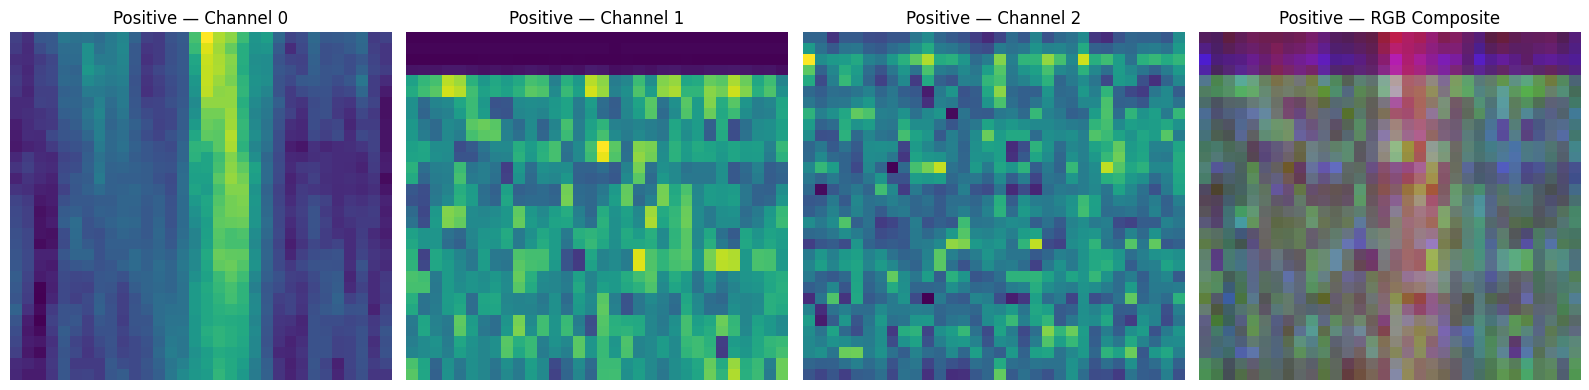

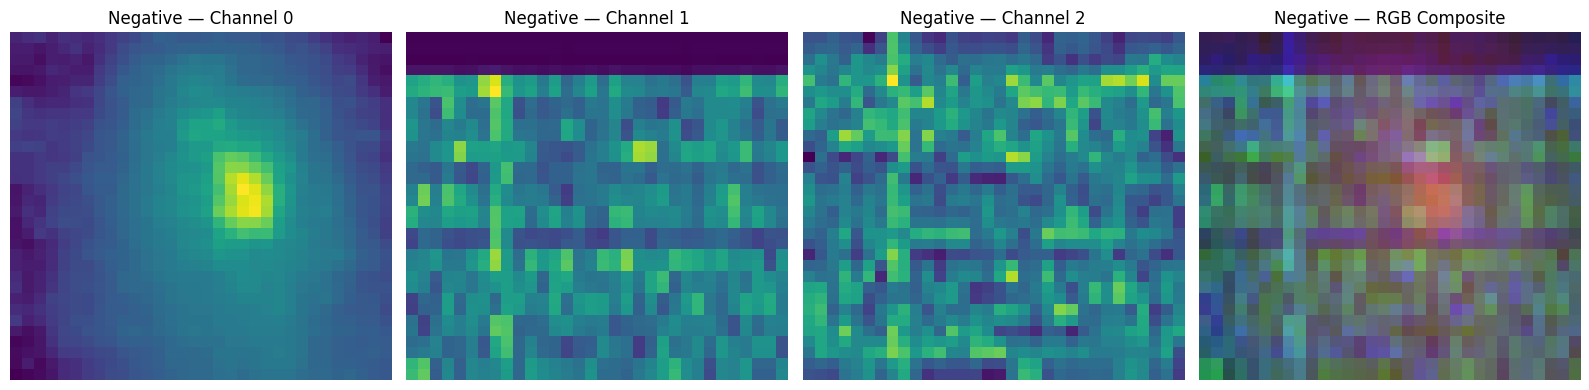


[7] BASIC DUPLICATE CHECK
Training samples: 50000
Unique training samples: 49994
Duplicate training samples: 6

Checking exact train/test overlap...
Exact train/test duplicate images: 5

HTRU1 DATASET SUMMARY
Training samples : 50,000
Test samples     : 10,000
Input shape      : (32, 32, 3)
Classes          : ['pulsar', 'nonpulsar']
Train positives  : 49,005
Train negatives  : 995
Test positives   : 9,801
Test negatives   : 199
Train/test exact overlap: 5

STEP 12 COMPLETE

Nothing has been trained yet.

Next we will decide the scientific experiment based on:
• class imbalance
• three-channel structure
• train/test integrity
• computational size

Then we will build the smallest model that answers a
meaningful question relevant to pulsar-candidate searches.



In [ ]:
# ================================================================
# STEP 12 — HTRU1 DATASET ANALYSIS
# ================================================================

import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from collections import Counter

print("=" * 70)
print("STEP 12 — HTRU1 DATASET ANALYSIS")
print("=" * 70)


# ================================================================
# 1. Load official test dataset
# ================================================================

print("\n" + "=" * 70)
print("[1] DOWNLOADING / LOADING TEST DATASET")
print("=" * 70)

test_data = HTRU1(
    DATA_DIR,
    train=False,
    download=True
)

print(
    "Number of test samples:",
    len(test_data)
)


# ================================================================
# 2. Convert training data to arrays
# ================================================================

print("\n" + "=" * 70)
print("[2] DATASET SHAPES")
print("=" * 70)

X_train = train_data.data
y_train = np.asarray(train_data.targets)

X_test = test_data.data
y_test = np.asarray(test_data.targets)

print(
    "Training X:",
    X_train.shape
)

print(
    "Training y:",
    y_train.shape
)

print(
    "Test X:",
    X_test.shape
)

print(
    "Test y:",
    y_test.shape
)


# ================================================================
# 3. Class distribution
# ================================================================

print("\n" + "=" * 70)
print("[3] CLASS DISTRIBUTION")
print("=" * 70)

print("\nTraining:")

train_counts = Counter(y_train)

for cls, count in sorted(train_counts.items()):

    print(
        f"Class {cls}: {count:,} "
        f"({100*count/len(y_train):.2f}%)"
    )


print("\nTest:")

test_counts = Counter(y_test)

for cls, count in sorted(test_counts.items()):

    print(
        f"Class {cls}: {count:,} "
        f"({100*count/len(y_test):.2f}%)"
    )


# ================================================================
# 4. Class names
# ================================================================

print("\n" + "=" * 70)
print("[4] CLASS NAMES")
print("=" * 70)

print(
    "Dataset classes:",
    train_data.classes
)


# ================================================================
# 5. Pixel/data statistics
# ================================================================

print("\n" + "=" * 70)
print("[5] DATA STATISTICS")
print("=" * 70)

print(
    "Training dtype:",
    X_train.dtype
)

print(
    "Training min:",
    X_train.min()
)

print(
    "Training max:",
    X_train.max()
)

print(
    "Training mean:",
    X_train.mean()
)

print(
    "Training std:",
    X_train.std()
)


# Per-channel statistics

channel_names = [
    "Channel 0",
    "Channel 1",
    "Channel 2"
]

print("\nPer-channel:")

for i, name in enumerate(channel_names):

    channel = X_train[:, :, :, i]

    print(
        f"{name}: "
        f"min={channel.min():.2f}, "
        f"max={channel.max():.2f}, "
        f"mean={channel.mean():.2f}, "
        f"std={channel.std():.2f}"
    )


# ================================================================
# 6. Visualize representative candidates
# ================================================================

print("\n" + "=" * 70)
print("[6] VISUALIZING THREE-CHANNEL REPRESENTATIONS")
print("=" * 70)

# Find one positive and one negative

positive_idx = np.where(y_train == 1)[0][0]
negative_idx = np.where(y_train == 0)[0][0]

print(
    "Positive example index:",
    positive_idx
)

print(
    "Negative example index:",
    negative_idx
)


# Positive example

fig, axes = plt.subplots(
    1, 4,
    figsize=(16, 4)
)

positive = X_train[positive_idx]

for c in range(3):

    axes[c].imshow(
        positive[:, :, c],
        aspect="auto"
    )

    axes[c].set_title(
        f"Positive — Channel {c}"
    )

    axes[c].axis("off")


axes[3].imshow(
    positive,
    aspect="auto"
)

axes[3].set_title(
    "Positive — RGB Composite"
)

axes[3].axis("off")

plt.tight_layout()
plt.show()


# Negative example

fig, axes = plt.subplots(
    1, 4,
    figsize=(16, 4)
)

negative = X_train[negative_idx]

for c in range(3):

    axes[c].imshow(
        negative[:, :, c],
        aspect="auto"
    )

    axes[c].set_title(
        f"Negative — Channel {c}"
    )

    axes[c].axis("off")


axes[3].imshow(
    negative,
    aspect="auto"
)

axes[3].set_title(
    "Negative — RGB Composite"
)

axes[3].axis("off")

plt.tight_layout()
plt.show()


# ================================================================
# 7. Check for duplicate samples
# ================================================================

print("\n" + "=" * 70)
print("[7] BASIC DUPLICATE CHECK")
print("=" * 70)

# Hash each complete image

train_hashes = []

for i in range(len(X_train)):

    train_hashes.append(
        hash(X_train[i].tobytes())
    )

unique_train = len(set(train_hashes))

print(
    "Training samples:",
    len(train_hashes)
)

print(
    "Unique training samples:",
    unique_train
)

print(
    "Duplicate training samples:",
    len(train_hashes) - unique_train
)


# ================================================================
# 8. Check train/test exact overlap
# ================================================================

print("\nChecking exact train/test overlap...")

test_hashes = set(
    hash(X_test[i].tobytes())
    for i in range(len(X_test))
)

overlap = sum(
    1
    for h in train_hashes
    if h in test_hashes
)

print(
    "Exact train/test duplicate images:",
    overlap
)


# ================================================================
# 9. Final dataset summary
# ================================================================

print("\n" + "=" * 70)
print("HTRU1 DATASET SUMMARY")
print("=" * 70)

print(
    f"Training samples : {len(X_train):,}"
)

print(
    f"Test samples     : {len(X_test):,}"
)

print(
    f"Input shape      : {X_train.shape[1:]}"
)

print(
    f"Classes          : {train_data.classes}"
)

print(
    f"Train positives  : {train_counts.get(1,0):,}"
)

print(
    f"Train negatives  : {train_counts.get(0,0):,}"
)

print(
    f"Test positives   : {test_counts.get(1,0):,}"
)

print(
    f"Test negatives   : {test_counts.get(0,0):,}"
)

print(
    f"Train/test exact overlap: {overlap}"
)

print("\n" + "=" * 70)
print("STEP 12 COMPLETE")
print("=" * 70)

print("""
Nothing has been trained yet.

Next we will decide the scientific experiment based on:
• class imbalance
• three-channel structure
• train/test integrity
• computational size

Then we will build the smallest model that answers a
meaningful question relevant to pulsar-candidate searches.
""")

In [ ]:
# ================================================================
# STEP 13 — LIGHTWEIGHT 3-CHANNEL CNN BASELINE
# ================================================================

import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)
import time

print("=" * 70)
print("STEP 13 — BUILDING 3-CHANNEL CNN BASELINE")
print("=" * 70)

# ------------------------------------------------
# 1. DEVICE
# ------------------------------------------------

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("\nDevice:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


# ------------------------------------------------
# 2. CONVERT DATA TO PYTORCH FORMAT
# ------------------------------------------------

# HTRU1:
# X shape = (N, 32, 32, 3)
# PyTorch CNN expects = (N, 3, 32, 32)

X_train_t = torch.tensor(
    X_train.transpose(0, 3, 1, 2),
    dtype=torch.float32
) / 255.0

X_test_t = torch.tensor(
    X_test.transpose(0, 3, 1, 2),
    dtype=torch.float32
) / 255.0

# Dataset labels:
# 0 = pulsar
# 1 = nonpulsar
#
# We will instead define:
# 1 = pulsar
# 0 = nonpulsar
#
# This makes the positive class the scientifically
# important minority class.

y_train_binary = (y_train == 0).astype(np.float32)
y_test_binary = (y_test == 0).astype(np.float32)

y_train_t = torch.tensor(y_train_binary, dtype=torch.float32)
y_test_t = torch.tensor(y_test_binary, dtype=torch.float32)

print("\nTensor shapes:")
print("X_train:", X_train_t.shape)
print("y_train:", y_train_t.shape)
print("X_test :", X_test_t.shape)
print("y_test :", y_test_t.shape)

print("\nPulsars:")
print("Train:", int(y_train_binary.sum()))
print("Test :", int(y_test_binary.sum()))


# ------------------------------------------------
# 3. DATA LOADERS
# ------------------------------------------------

BATCH_SIZE = 256

train_dataset = TensorDataset(
    X_train_t,
    y_train_t
)

test_dataset = TensorDataset(
    X_test_t,
    y_test_t
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("\nBatch size:", BATCH_SIZE)
print("Training batches:", len(train_loader))
print("Test batches:", len(test_loader))


# ------------------------------------------------
# 4. LIGHTWEIGHT CNN
# ------------------------------------------------

class PulsarCNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(

            # 32 x 32
            nn.Conv2d(
                in_channels=3,
                out_channels=32,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # 16 x 16
            nn.Conv2d(
                in_channels=32,
                out_channels=64,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # 8 x 8
            nn.Conv2d(
                in_channels=64,
                out_channels=128,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),

            # 8 x 8 x 128 → 128
            nn.AdaptiveAvgPool2d(1)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, 1)
        )

    def forward(self, x):

        x = self.features(x)
        x = self.classifier(x)

        return x.squeeze(1)


model = PulsarCNN().to(device)

print("\nModel:")
print(model)


# ------------------------------------------------
# 5. PARAMETER COUNT
# ------------------------------------------------

num_parameters = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("\nTrainable parameters:", f"{num_parameters:,}")


# ------------------------------------------------
# 6. CLASS WEIGHT
# ------------------------------------------------

n_pulsar = y_train_binary.sum()
n_nonpulsar = len(y_train_binary) - n_pulsar

# Positive class = pulsar
#
# Weight positive class so that the rare pulsar
# class receives stronger training signal.

pos_weight = n_nonpulsar / n_pulsar

pos_weight_tensor = torch.tensor(
    [pos_weight],
    dtype=torch.float32,
    device=device
)

print("\nClass statistics:")
print("Pulsars   :", int(n_pulsar))
print("Nonpulsars:", int(n_nonpulsar))
print("Positive-class weight:", round(pos_weight, 3))


# ------------------------------------------------
# 7. LOSS + OPTIMIZER
# ------------------------------------------------

criterion = nn.BCEWithLogitsLoss(
    pos_weight=pos_weight_tensor
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)


# ------------------------------------------------
# 8. TRAINING
# ------------------------------------------------

EPOCHS = 8

print("\nTraining for", EPOCHS, "epochs...")
print("-" * 70)

for epoch in range(EPOCHS):

    model.train()

    running_loss = 0.0
    n_samples = 0

    start_time = time.time()

    for batch_x, batch_y in train_loader:

        batch_x = batch_x.to(
            device,
            non_blocking=True
        )

        batch_y = batch_y.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad()

        logits = model(batch_x)

        loss = criterion(
            logits,
            batch_y
        )

        loss.backward()

        optimizer.step()

        running_loss += (
            loss.item() * batch_x.size(0)
        )

        n_samples += batch_x.size(0)

    epoch_loss = running_loss / n_samples

    elapsed = time.time() - start_time

    print(
        f"Epoch {epoch+1:02d}/{EPOCHS} | "
        f"Loss: {epoch_loss:.5f} | "
        f"Time: {elapsed:.1f}s"
    )


# ------------------------------------------------
# 9. TEST INFERENCE
# ------------------------------------------------

print("\n" + "=" * 70)
print("TEST SET EVALUATION")
print("=" * 70)

model.eval()

all_probabilities = []
all_targets = []

inference_start = time.time()

with torch.no_grad():

    for batch_x, batch_y in test_loader:

        batch_x = batch_x.to(
            device,
            non_blocking=True
        )

        logits = model(batch_x)

        probabilities = torch.sigmoid(logits)

        all_probabilities.extend(
            probabilities.cpu().numpy()
        )

        all_targets.extend(
            batch_y.numpy()
        )

inference_time = time.time() - inference_start

y_prob = np.asarray(all_probabilities)
y_true = np.asarray(all_targets)


# ------------------------------------------------
# 10. THRESHOLD = 0.5
# ------------------------------------------------

threshold = 0.5

y_pred = (
    y_prob >= threshold
).astype(int)


# ------------------------------------------------
# 11. METRICS
# ------------------------------------------------

precision = precision_score(
    y_true,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_true,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_true,
    y_pred,
    zero_division=0
)

roc_auc = roc_auc_score(
    y_true,
    y_prob
)

pr_auc = average_precision_score(
    y_true,
    y_prob
)

cm = confusion_matrix(
    y_true,
    y_pred
)


# ------------------------------------------------
# 12. RESULTS
# ------------------------------------------------

print("\nThreshold:", threshold)

print("\nMetrics:")
print("Precision :", f"{precision:.4f}")
print("Recall    :", f"{recall:.4f}")
print("F1        :", f"{f1:.4f}")
print("ROC-AUC   :", f"{roc_auc:.4f}")
print("PR-AUC    :", f"{pr_auc:.4f}")

print("\nConfusion matrix:")
print(cm)

print("\nInference:")
print("Total test samples:", len(y_true))
print("Inference time    :", f"{inference_time:.3f} s")
print(
    "Samples/sec       :",
    f"{len(y_true)/inference_time:.1f}"
)

print("\n" + "=" * 70)
print("STEP 13 COMPLETE")
print("=" * 70)

STEP 13 — BUILDING 3-CHANNEL CNN BASELINE

Device: cuda
GPU: Tesla T4


NameError: name 'X_train' is not defined

In [ ]:
# ================================================================
# STEP 13 — LOAD HTRU1 + BUILD 3-CHANNEL CNN BASELINE
# ================================================================

import sys
import os
import numpy as np
import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

import time

print("=" * 70)
print("STEP 13 — 3-CHANNEL CNN BASELINE")
print("=" * 70)


# ================================================================
# 1. LOAD HTRU1 DATASET
# ================================================================

REPO_DIR = "/content/HTRU1"
DATA_DIR = "/content/htru1_data"

if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)

from htru1 import HTRU1

print("\nLoading HTRU1...")

train_dataset_htru = HTRU1(
    DATA_DIR,
    train=True,
    download=True
)

test_dataset_htru = HTRU1(
    DATA_DIR,
    train=False,
    download=True
)

print("Train samples:", len(train_dataset_htru))
print("Test samples :", len(test_dataset_htru))


# ================================================================
# 2. EXTRACT NUMPY ARRAYS
# ================================================================

def dataset_to_numpy(dataset):

    X = np.stack([
        np.asarray(dataset[i][0])
        for i in range(len(dataset))
    ])

    y = np.asarray([
        dataset[i][1]
        for i in range(len(dataset))
    ])

    return X, y


print("\nExtracting training data...")

X_train, y_train_original = dataset_to_numpy(
    train_dataset_htru
)

print("Extracting test data...")

X_test, y_test_original = dataset_to_numpy(
    test_dataset_htru
)


print("\nOriginal shapes:")
print("X_train:", X_train.shape)
print("y_train:", y_train_original.shape)
print("X_test :", X_test.shape)
print("y_test :", y_test_original.shape)


# ================================================================
# 3. DATASET LABEL CONVENTION
# ================================================================
#
# HTRU1:
#   class 0 = pulsar
#   class 1 = nonpulsar
#
# For our ML experiment:
#   1 = pulsar
#   0 = nonpulsar
#
# This makes the scientifically important minority class
# the positive class.

y_train = (y_train_original == 0).astype(np.float32)
y_test = (y_test_original == 0).astype(np.float32)

print("\nClass distribution:")
print(
    "Train pulsars   :",
    int(y_train.sum())
)

print(
    "Train nonpulsars:",
    int(len(y_train) - y_train.sum())
)

print(
    "Test pulsars    :",
    int(y_test.sum())
)

print(
    "Test nonpulsars :",
    int(len(y_test) - y_test.sum())
)


# ================================================================
# 4. CONVERT TO PYTORCH FORMAT
# ================================================================

# HTRU1:
# (N, 32, 32, 3)
#
# PyTorch CNN:
# (N, 3, 32, 32)

X_train_t = torch.tensor(
    X_train.transpose(0, 3, 1, 2),
    dtype=torch.float32
) / 255.0

X_test_t = torch.tensor(
    X_test.transpose(0, 3, 1, 2),
    dtype=torch.float32
) / 255.0

y_train_t = torch.tensor(
    y_train,
    dtype=torch.float32
)

y_test_t = torch.tensor(
    y_test,
    dtype=torch.float32
)

print("\nPyTorch shapes:")
print("X_train:", X_train_t.shape)
print("X_test :", X_test_t.shape)


# ================================================================
# 5. DEVICE
# ================================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("\nDevice:", device)

if torch.cuda.is_available():
    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )


# ================================================================
# 6. DATA LOADERS
# ================================================================

BATCH_SIZE = 256

train_dataset = TensorDataset(
    X_train_t,
    y_train_t
)

test_dataset = TensorDataset(
    X_test_t,
    y_test_t
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("\nBatch size:", BATCH_SIZE)
print("Training batches:", len(train_loader))
print("Test batches:", len(test_loader))


# ================================================================
# 7. LIGHTWEIGHT CNN
# ================================================================

class PulsarCNN(nn.Module):

    def __init__(self):

        super().__init__()

        self.features = nn.Sequential(

            nn.Conv2d(
                3, 32,
                kernel_size=3,
                padding=1
            ),

            nn.ReLU(),

            nn.MaxPool2d(2),

            nn.Conv2d(
                32, 64,
                kernel_size=3,
                padding=1
            ),

            nn.ReLU(),

            nn.MaxPool2d(2),

            nn.Conv2d(
                64, 128,
                kernel_size=3,
                padding=1
            ),

            nn.ReLU(),

            nn.AdaptiveAvgPool2d(1)
        )

        self.classifier = nn.Sequential(

            nn.Flatten(),

            nn.Linear(128, 64),

            nn.ReLU(),

            nn.Dropout(0.3),

            nn.Linear(64, 1)
        )


    def forward(self, x):

        x = self.features(x)

        x = self.classifier(x)

        return x.squeeze(1)


model = PulsarCNN().to(device)

print("\nModel:")
print(model)


# ================================================================
# 8. PARAMETER COUNT
# ================================================================

num_parameters = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(
    "\nTrainable parameters:",
    f"{num_parameters:,}"
)


# ================================================================
# 9. CLASS WEIGHT
# ================================================================

n_pulsar = y_train.sum()

n_nonpulsar = (
    len(y_train) - n_pulsar
)

pos_weight = (
    n_nonpulsar / n_pulsar
)

pos_weight_tensor = torch.tensor(
    [pos_weight],
    dtype=torch.float32,
    device=device
)

print("\nClass weighting:")
print("Pulsars   :", int(n_pulsar))
print("Nonpulsars:", int(n_nonpulsar))
print(
    "Positive-class weight:",
    round(float(pos_weight), 3)
)


# ================================================================
# 10. LOSS + OPTIMIZER
# ================================================================

criterion = nn.BCEWithLogitsLoss(
    pos_weight=pos_weight_tensor
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)


# ================================================================
# 11. TRAIN
# ================================================================

EPOCHS = 8

print("\n" + "=" * 70)
print("TRAINING")
print("=" * 70)

for epoch in range(EPOCHS):

    model.train()

    running_loss = 0.0
    n_samples = 0

    start_time = time.time()

    for batch_x, batch_y in train_loader:

        batch_x = batch_x.to(
            device,
            non_blocking=True
        )

        batch_y = batch_y.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad()

        logits = model(batch_x)

        loss = criterion(
            logits,
            batch_y
        )

        loss.backward()

        optimizer.step()

        running_loss += (
            loss.item() * batch_x.size(0)
        )

        n_samples += batch_x.size(0)

    epoch_loss = (
        running_loss / n_samples
    )

    elapsed = time.time() - start_time

    print(
        f"Epoch {epoch+1:02d}/{EPOCHS} | "
        f"Loss: {epoch_loss:.5f} | "
        f"Time: {elapsed:.1f}s"
    )


# ================================================================
# 12. TEST INFERENCE
# ================================================================

print("\n" + "=" * 70)
print("TEST SET EVALUATION")
print("=" * 70)

model.eval()

all_probabilities = []
all_targets = []

inference_start = time.time()

with torch.no_grad():

    for batch_x, batch_y in test_loader:

        batch_x = batch_x.to(
            device,
            non_blocking=True
        )

        logits = model(batch_x)

        probabilities = torch.sigmoid(
            logits
        )

        all_probabilities.extend(
            probabilities.cpu().numpy()
        )

        all_targets.extend(
            batch_y.numpy()
        )

inference_time = (
    time.time() - inference_start
)

y_prob = np.asarray(
    all_probabilities
)

y_true = np.asarray(
    all_targets
)


# ================================================================
# 13. THRESHOLD = 0.5
# ================================================================

threshold = 0.5

y_pred = (
    y_prob >= threshold
).astype(int)


# ================================================================
# 14. METRICS
# ================================================================

precision = precision_score(
    y_true,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_true,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_true,
    y_pred,
    zero_division=0
)

roc_auc = roc_auc_score(
    y_true,
    y_prob
)

pr_auc = average_precision_score(
    y_true,
    y_prob
)

cm = confusion_matrix(
    y_true,
    y_pred
)


# ================================================================
# 15. RESULTS
# ================================================================

print("\nThreshold:", threshold)

print("\nMetrics:")
print(
    "Precision :",
    f"{precision:.4f}"
)

print(
    "Recall    :",
    f"{recall:.4f}"
)

print(
    "F1        :",
    f"{f1:.4f}"
)

print(
    "ROC-AUC   :",
    f"{roc_auc:.4f}"
)

print(
    "PR-AUC    :",
    f"{pr_auc:.4f}"
)

print("\nConfusion matrix:")
print(cm)

print("\nInference:")
print(
    "Total test samples:",
    len(y_true)
)

print(
    "Inference time:",
    f"{inference_time:.3f} s"
)

print(
    "Samples/sec:",
    f"{len(y_true)/inference_time:.1f}"
)

print("\n" + "=" * 70)
print("STEP 13 COMPLETE")
print("=" * 70)

STEP 13 — 3-CHANNEL CNN BASELINE

Loading HTRU1...
Files already downloaded and verified
Files already downloaded and verified
Train samples: 50000
Test samples : 10000

Extracting training data...
Extracting test data...

Original shapes:
X_train: (50000, 32, 32, 3)
y_train: (50000,)
X_test : (10000, 32, 32, 3)
y_test : (10000,)

Class distribution:
Train pulsars   : 995
Train nonpulsars: 49005
Test pulsars    : 199
Test nonpulsars : 9801

PyTorch shapes:
X_train: torch.Size([50000, 3, 32, 32])
X_test : torch.Size([10000, 3, 32, 32])

Device: cuda
GPU: Tesla T4

Batch size: 256
Training batches: 196
Test batches: 40

Model:
PulsarCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1

STEP 14 — SINGLE-VIEW vs MULTI-VIEW ABLATION

Device: cuda
GPU: Tesla T4

Available input:
Training: torch.Size([50000, 3, 32, 32])
Test    : torch.Size([10000, 3, 32, 32])


EXPERIMENT: Channel 0
CHANNELS : [0]
Input shape: (50000, 1, 32, 32)


NameError: name 'y_train_binary' is not defined

In [ ]:
# ================================================================
# STEP 14 — SINGLE-VIEW vs MULTI-VIEW ABLATION
# ================================================================

import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

import pandas as pd
import time


print("=" * 70)
print("STEP 14 — SINGLE-VIEW vs MULTI-VIEW ABLATION")
print("=" * 70)


# ================================================================
# 1. DEVICE
# ================================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("\nDevice:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


# ================================================================
# 2. VERIFY DATA
# ================================================================

print("\nAvailable input:")
print("Training:", X_train_t.shape)
print("Test    :", X_test_t.shape)

print("\nLabels:")
print("Training:", y_train_t.shape)
print("Test    :", y_test_t.shape)


# ================================================================
# 3. CNN ARCHITECTURE
# ================================================================

class PulsarCNN(nn.Module):

    def __init__(self, in_channels=3):

        super().__init__()

        self.features = nn.Sequential(

            nn.Conv2d(
                in_channels,
                32,
                kernel_size=3,
                padding=1
            ),

            nn.ReLU(),

            nn.MaxPool2d(2),

            nn.Conv2d(
                32,
                64,
                kernel_size=3,
                padding=1
            ),

            nn.ReLU(),

            nn.MaxPool2d(2),

            nn.Conv2d(
                64,
                128,
                kernel_size=3,
                padding=1
            ),

            nn.ReLU(),

            nn.AdaptiveAvgPool2d(1)
        )

        self.classifier = nn.Sequential(

            nn.Flatten(),

            nn.Linear(
                128,
                64
            ),

            nn.ReLU(),

            nn.Dropout(0.3),

            nn.Linear(
                64,
                1
            )
        )


    def forward(self, x):

        x = self.features(x)

        x = self.classifier(x)

        return x.squeeze(1)


# ================================================================
# 4. EXPERIMENT CONFIGURATION
# ================================================================

experiments = {

    "Channel 0": [0],

    "Channel 1": [1],

    "Channel 2": [2],

    "All 3 channels": [0, 1, 2]
}


EPOCHS = 8
BATCH_SIZE = 256
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4


# ================================================================
# 5. CLASS WEIGHT
# ================================================================

# y_train_t:
#   1 = pulsar
#   0 = nonpulsar

n_pulsar = float(
    y_train_t.sum().item()
)

n_nonpulsar = float(
    len(y_train_t) - n_pulsar
)

pos_weight = (
    n_nonpulsar / n_pulsar
)

print("\nClass weighting:")
print("Pulsars   :", int(n_pulsar))
print("Nonpulsars:", int(n_nonpulsar))
print(
    "Positive-class weight:",
    round(pos_weight, 3)
)


# ================================================================
# 6. EXPERIMENT FUNCTION
# ================================================================

def run_experiment(
    experiment_name,
    channels
):

    print("\n")
    print("=" * 70)
    print("EXPERIMENT:", experiment_name)
    print("CHANNELS :", channels)
    print("=" * 70)


    # ------------------------------------------------------------
    # Select channels
    # ------------------------------------------------------------

    Xtr = X_train_t[:, channels, :, :]
    Xte = X_test_t[:, channels, :, :]

    print(
        "Input shape:",
        tuple(Xtr.shape)
    )


    # ------------------------------------------------------------
    # DataLoaders
    # ------------------------------------------------------------

    train_ds = TensorDataset(
        Xtr,
        y_train_t
    )

    test_ds = TensorDataset(
        Xte,
        y_test_t
    )

    train_loader = DataLoader(
        train_ds,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=2,
        pin_memory=True
    )

    test_loader = DataLoader(
        test_ds,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=2,
        pin_memory=True
    )


    # ------------------------------------------------------------
    # Model
    # ------------------------------------------------------------

    model = PulsarCNN(
        in_channels=len(channels)
    ).to(device)


    # ------------------------------------------------------------
    # Parameter count
    # ------------------------------------------------------------

    parameters = sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )


    # ------------------------------------------------------------
    # Loss
    # ------------------------------------------------------------

    criterion = nn.BCEWithLogitsLoss(
        pos_weight=torch.tensor(
            [pos_weight],
            dtype=torch.float32,
            device=device
        )
    )


    # ------------------------------------------------------------
    # Optimizer
    # ------------------------------------------------------------

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )


    # ------------------------------------------------------------
    # Training
    # ------------------------------------------------------------

    training_start = time.time()

    for epoch in range(EPOCHS):

        model.train()

        running_loss = 0.0
        n_samples = 0

        for batch_x, batch_y in train_loader:

            batch_x = batch_x.to(
                device,
                non_blocking=True
            )

            batch_y = batch_y.to(
                device,
                non_blocking=True
            )

            optimizer.zero_grad()

            logits = model(batch_x)

            loss = criterion(
                logits,
                batch_y
            )

            loss.backward()

            optimizer.step()

            running_loss += (
                loss.item()
                * batch_x.size(0)
            )

            n_samples += batch_x.size(0)

        epoch_loss = (
            running_loss / n_samples
        )

        print(
            f"Epoch {epoch+1:02d}/{EPOCHS} | "
            f"Loss: {epoch_loss:.5f}"
        )

    training_time = (
        time.time() - training_start
    )


    # ------------------------------------------------------------
    # Inference
    # ------------------------------------------------------------

    model.eval()

    probabilities = []
    targets = []

    inference_start = time.time()

    with torch.no_grad():

        for batch_x, batch_y in test_loader:

            batch_x = batch_x.to(
                device,
                non_blocking=True
            )

            logits = model(batch_x)

            prob = torch.sigmoid(
                logits
            )

            probabilities.extend(
                prob.cpu().numpy()
            )

            targets.extend(
                batch_y.numpy()
            )

    inference_time = (
        time.time() - inference_start
    )

    y_prob_exp = np.asarray(
        probabilities
    )

    y_true_exp = np.asarray(
        targets
    )


    # ------------------------------------------------------------
    # Classification threshold
    # ------------------------------------------------------------

    threshold = 0.5

    y_pred_exp = (
        y_prob_exp >= threshold
    ).astype(int)


    # ------------------------------------------------------------
    # Metrics
    # ------------------------------------------------------------

    precision = precision_score(
        y_true_exp,
        y_pred_exp,
        zero_division=0
    )

    recall = recall_score(
        y_true_exp,
        y_pred_exp,
        zero_division=0
    )

    f1 = f1_score(
        y_true_exp,
        y_pred_exp,
        zero_division=0
    )

    roc_auc = roc_auc_score(
        y_true_exp,
        y_prob_exp
    )

    pr_auc = average_precision_score(
        y_true_exp,
        y_prob_exp
    )

    cm = confusion_matrix(
        y_true_exp,
        y_pred_exp
    )

    tn, fp, fn, tp = cm.ravel()

    fpr = fp / (fp + tn)


    # ------------------------------------------------------------
    # Print results
    # ------------------------------------------------------------

    print("\nRESULTS")

    print(
        "Parameters:",
        f"{parameters:,}"
    )

    print(
        "Precision :",
        f"{precision:.4f}"
    )

    print(
        "Recall    :",
        f"{recall:.4f}"
    )

    print(
        "F1        :",
        f"{f1:.4f}"
    )

    print(
        "ROC-AUC   :",
        f"{roc_auc:.4f}"
    )

    print(
        "PR-AUC    :",
        f"{pr_auc:.4f}"
    )

    print(
        "FPR       :",
        f"{fpr:.4f}"
    )

    print("\nConfusion matrix:")
    print(cm)

    print(
        "\nTraining time:",
        f"{training_time:.2f} s"
    )

    print(
        "Inference time:",
        f"{inference_time:.3f} s"
    )

    print(
        "Throughput:",
        f"{len(y_true_exp)/inference_time:.1f}",
        "samples/s"
    )


    # ------------------------------------------------------------
    # Return
    # ------------------------------------------------------------

    return {

        "Model": experiment_name,

        "Channels": str(channels),

        "Parameters": parameters,

        "Precision": precision,

        "Recall": recall,

        "F1": f1,

        "ROC-AUC": roc_auc,

        "PR-AUC": pr_auc,

        "FPR": fpr,

        "TP": int(tp),

        "FP": int(fp),

        "FN": int(fn),

        "TN": int(tn),

        "Training_Time_s": training_time,

        "Inference_Time_s": inference_time,

        "Samples_per_s":
            len(y_true_exp)
            / inference_time
    }


# ================================================================
# 7. RUN EXPERIMENTS
# ================================================================

results = []

for name, channels in experiments.items():

    result = run_experiment(
        name,
        channels
    )

    results.append(result)


# ================================================================
# 8. RESULTS TABLE
# ================================================================

results_df = pd.DataFrame(
    results
)

print("\n")
print("=" * 70)
print("FINAL ABLATION RESULTS")
print("=" * 70)

display(
    results_df[
        [
            "Model",
            "Parameters",
            "Precision",
            "Recall",
            "F1",
            "ROC-AUC",
            "PR-AUC",
            "FPR",
            "TP",
            "FP",
            "FN",
            "TN"
        ]
    ].round(4)
)


# ================================================================
# 9. SAVE
# ================================================================

RESULT_PATH = (
    "/content/"
    "htru1_multiview_ablation_results.csv"
)

results_df.to_csv(
    RESULT_PATH,
    index=False
)

print(
    "\nResults saved to:",
    RESULT_PATH
)


# ================================================================
# 10. PR-AUC SUMMARY
# ================================================================

print("\nPR-AUC comparison:")

for _, row in results_df.iterrows():

    print(
        f"{row['Model']:18s} "
        f"{row['PR-AUC']:.4f}"
    )


print("\n" + "=" * 70)
print("STEP 14 COMPLETE")
print("=" * 70)

STEP 14 — SINGLE-VIEW vs MULTI-VIEW ABLATION

Device: cuda
GPU: Tesla T4

Available input:
Training: torch.Size([50000, 3, 32, 32])
Test    : torch.Size([10000, 3, 32, 32])

Labels:
Training: torch.Size([50000])
Test    : torch.Size([10000])

Class weighting:
Pulsars   : 995
Nonpulsars: 49005
Positive-class weight: 49.251


EXPERIMENT: Channel 0
CHANNELS : [0]
Input shape: (50000, 1, 32, 32)
Epoch 01/8 | Loss: 0.76977
Epoch 02/8 | Loss: 0.34860
Epoch 03/8 | Loss: 0.31303
Epoch 04/8 | Loss: 0.30311
Epoch 05/8 | Loss: 0.27973
Epoch 06/8 | Loss: 0.24934
Epoch 07/8 | Loss: 0.24228
Epoch 08/8 | Loss: 0.24421

RESULTS
Parameters: 100,993
Precision : 0.5508
Recall    : 0.8442
F1        : 0.6667
ROC-AUC   : 0.9913
PR-AUC    : 0.7789
FPR       : 0.0140

Confusion matrix:
[[9664  137]
 [  31  168]]

Training time: 17.65 s
Inference time: 0.352 s
Throughput: 28445.2 samples/s


EXPERIMENT: Channel 1
CHANNELS : [1]
Input shape: (50000, 1, 32, 32)
Epoch 01/8 | Loss: 0.75005
Epoch 02/8 | Loss: 0.472

,Model,Parameters,Precision,Recall,F1,ROC-AUC,PR-AUC,FPR,TP,FP,FN,TN
0,Channel 0,100993,0.5508,0.8442,0.6667,0.9913,0.7789,0.0140,168,137,31,9664
1,Channel 1,100993,0.4895,0.8191,0.6128,0.9696,0.7655,0.0173,163,170,36,9631
2,Channel 2,100993,0.5491,0.7588,0.6371,0.9546,0.7043,0.0127,151,124,48,9677
3,All 3 channels,101569,0.4056,0.9497,0.5684,0.9932,0.8366,0.0283,189,277,10,9524



Results saved to: /content/htru1_multiview_ablation_results.csv

PR-AUC comparison:
Channel 0          0.7789
Channel 1          0.7655
Channel 2          0.7043
All 3 channels     0.8366

STEP 14 COMPLETE


STEP 15 — PULSAR CANDIDATE TRIAGE

Device: cuda
GPU: Tesla T4

Positive-class weight: 49.251


MODEL: Channel 0
Training time: 15.38 s
Inference time: 0.349 s


MODEL: Channel 1
Training time: 15.32 s
Inference time: 0.582 s


MODEL: Channel 2
Training time: 15.62 s
Inference time: 0.361 s


MODEL: All 3 channels
Training time: 16.36 s
Inference time: 0.460 s

Predictions saved to: /content/htru1_model_predictions.npz


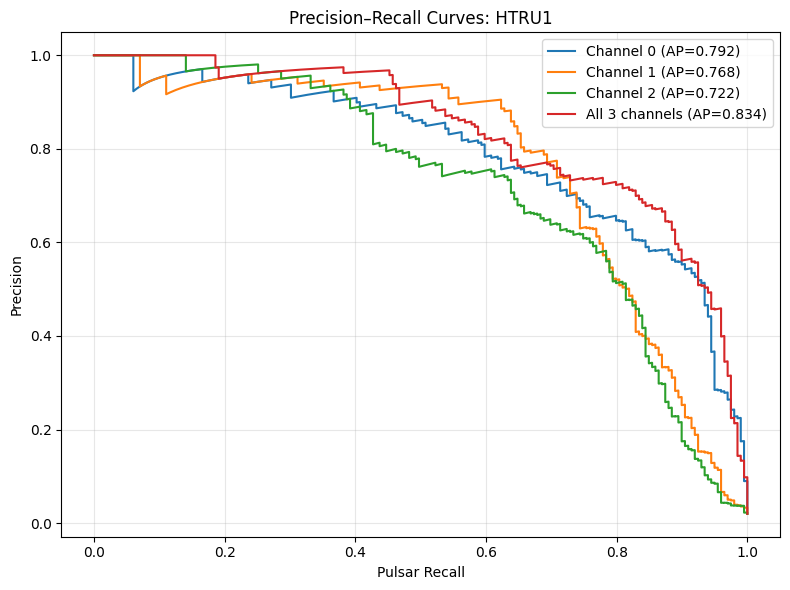



OPERATING POINTS


,Model,Target_Recall,Threshold,Precision,Recall,FPR,Candidates_Selected,Candidate_Fraction,Candidate_Reduction
0,Channel 0,0.90,0.8341,0.5538,0.9045,0.0148,325,0.0325,0.9675
1,Channel 0,0.95,0.3781,0.2857,0.9548,0.0485,665,0.0665,0.9335
2,Channel 0,0.99,0.1104,0.1752,0.9950,0.0951,1130,0.1130,0.8870
3,Channel 1,0.90,0.0600,0.2532,0.9045,0.0542,711,0.0711,0.9289
4,Channel 1,0.95,0.0288,0.1186,0.9548,0.1441,1602,0.1602,0.8398
5,Channel 1,0.99,0.0100,0.0356,0.9950,0.5480,5569,0.5569,0.4431
6,Channel 2,0.90,0.2003,0.1754,0.9045,0.0863,1026,0.1026,0.8974
7,Channel 2,0.95,0.0853,0.0844,0.9548,0.2104,2252,0.2252,0.7748
8,Channel 2,0.99,0.0302,0.0370,0.9950,0.5257,5350,0.5350,0.4650
9,All 3 channels,0.90,0.4279,0.5625,0.9045,0.0143,320,0.0320,0.9680



Operating points saved to: /content/htru1_candidate_triage_operating_points.csv


ALL-3-CHANNEL MODEL


,Target_Recall,Threshold,Precision,Recall,FPR,Candidates_Selected,Candidate_Reduction
9,0.90,0.4279,0.5625,0.9045,0.0143,320,0.9680
10,0.95,0.2139,0.4578,0.9548,0.0230,415,0.9585
11,0.99,0.0154,0.1337,0.9950,0.1309,1481,0.8519



STEP 15 COMPLETE

We have now measured how the classifier behaves as a
candidate-triage system rather than only at an arbitrary
0.5 classification threshold.

The key quantities for the paper are:

1. Pulsar recall
2. Precision
3. False-positive rate
4. Number of candidates retained
5. Candidate reduction
6. Precision–recall area

The next step will use these results to determine the
scientific conclusion and construct the compact paper.



In [ ]:
# ================================================================
# STEP 15 — PULSAR CANDIDATE TRIAGE / THRESHOLD ANALYSIS
# ================================================================

import numpy as np
import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    precision_recall_curve,
    average_precision_score,
    roc_auc_score
)

import pandas as pd
import matplotlib.pyplot as plt
import time


print("=" * 70)
print("STEP 15 — PULSAR CANDIDATE TRIAGE")
print("=" * 70)


# ================================================================
# 1. DEVICE
# ================================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("\nDevice:", device)

if torch.cuda.is_available():
    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )


# ================================================================
# 2. MODEL
# ================================================================

class PulsarCNN(nn.Module):

    def __init__(self, in_channels=3):

        super().__init__()

        self.features = nn.Sequential(

            nn.Conv2d(
                in_channels,
                32,
                kernel_size=3,
                padding=1
            ),

            nn.ReLU(),

            nn.MaxPool2d(2),

            nn.Conv2d(
                32,
                64,
                kernel_size=3,
                padding=1
            ),

            nn.ReLU(),

            nn.MaxPool2d(2),

            nn.Conv2d(
                64,
                128,
                kernel_size=3,
                padding=1
            ),

            nn.ReLU(),

            nn.AdaptiveAvgPool2d(1)
        )

        self.classifier = nn.Sequential(

            nn.Flatten(),

            nn.Linear(
                128,
                64
            ),

            nn.ReLU(),

            nn.Dropout(0.3),

            nn.Linear(
                64,
                1
            )
        )


    def forward(self, x):

        x = self.features(x)

        x = self.classifier(x)

        return x.squeeze(1)


# ================================================================
# 3. FIXED EXPERIMENT SETTINGS
# ================================================================

EPOCHS = 8
BATCH_SIZE = 256
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4

experiments = {

    "Channel 0": [0],

    "Channel 1": [1],

    "Channel 2": [2],

    "All 3 channels": [0, 1, 2]
}


# ================================================================
# 4. CLASS WEIGHT
# ================================================================

n_pulsar = float(
    y_train_t.sum().item()
)

n_nonpulsar = float(
    len(y_train_t) - n_pulsar
)

pos_weight = (
    n_nonpulsar / n_pulsar
)

print(
    "\nPositive-class weight:",
    round(pos_weight, 3)
)


# ================================================================
# 5. TRAIN + SAVE PREDICTIONS
# ================================================================

prediction_store = {}

training_summary = []


for experiment_name, channels in experiments.items():

    print("\n")
    print("=" * 70)
    print("MODEL:", experiment_name)
    print("=" * 70)


    # ------------------------------------------------------------
    # Select input channels
    # ------------------------------------------------------------

    Xtr = X_train_t[:, channels, :, :]
    Xte = X_test_t[:, channels, :, :]


    train_ds = TensorDataset(
        Xtr,
        y_train_t
    )

    test_ds = TensorDataset(
        Xte,
        y_test_t
    )


    train_loader = DataLoader(
        train_ds,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=2,
        pin_memory=True
    )

    test_loader = DataLoader(
        test_ds,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=2,
        pin_memory=True
    )


    # ------------------------------------------------------------
    # Create model
    # ------------------------------------------------------------

    model = PulsarCNN(
        in_channels=len(channels)
    ).to(device)


    # ------------------------------------------------------------
    # Loss
    # ------------------------------------------------------------

    criterion = nn.BCEWithLogitsLoss(
        pos_weight=torch.tensor(
            [pos_weight],
            dtype=torch.float32,
            device=device
        )
    )


    # ------------------------------------------------------------
    # Optimizer
    # ------------------------------------------------------------

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )


    # ------------------------------------------------------------
    # Training
    # ------------------------------------------------------------

    start = time.time()

    for epoch in range(EPOCHS):

        model.train()

        for batch_x, batch_y in train_loader:

            batch_x = batch_x.to(
                device,
                non_blocking=True
            )

            batch_y = batch_y.to(
                device,
                non_blocking=True
            )

            optimizer.zero_grad()

            logits = model(batch_x)

            loss = criterion(
                logits,
                batch_y
            )

            loss.backward()

            optimizer.step()


    training_time = time.time() - start


    # ------------------------------------------------------------
    # Test predictions
    # ------------------------------------------------------------

    model.eval()

    probabilities = []

    inference_start = time.time()

    with torch.no_grad():

        for batch_x, batch_y in test_loader:

            batch_x = batch_x.to(
                device,
                non_blocking=True
            )

            logits = model(batch_x)

            prob = torch.sigmoid(logits)

            probabilities.extend(
                prob.cpu().numpy()
            )

    inference_time = (
        time.time()
        - inference_start
    )


    y_prob = np.asarray(
        probabilities
    )

    y_true = y_test_t.numpy()


    prediction_store[experiment_name] = {
        "probabilities": y_prob,
        "targets": y_true
    }


    training_summary.append({

        "Model": experiment_name,

        "Training_Time_s":
            training_time,

        "Inference_Time_s":
            inference_time
    })


    print(
        "Training time:",
        f"{training_time:.2f} s"
    )

    print(
        "Inference time:",
        f"{inference_time:.3f} s"
    )


# ================================================================
# 6. SAVE RAW PREDICTIONS
# ================================================================

prediction_path = (
    "/content/"
    "htru1_model_predictions.npz"
)

np.savez(
    prediction_path,

    y_true=y_test_t.numpy(),

    channel0=
        prediction_store[
            "Channel 0"
        ]["probabilities"],

    channel1=
        prediction_store[
            "Channel 1"
        ]["probabilities"],

    channel2=
        prediction_store[
            "Channel 2"
        ]["probabilities"],

    all3=
        prediction_store[
            "All 3 channels"
        ]["probabilities"]
)

print(
    "\nPredictions saved to:",
    prediction_path
)


# ================================================================
# 7. PRECISION-RECALL CURVES
# ================================================================

plt.figure(
    figsize=(8, 6)
)

for experiment_name, data in prediction_store.items():

    precision, recall, thresholds = (
        precision_recall_curve(
            data["targets"],
            data["probabilities"]
        )
    )

    pr_auc = average_precision_score(
        data["targets"],
        data["probabilities"]
    )

    plt.plot(
        recall,
        precision,
        label=(
            f"{experiment_name} "
            f"(AP={pr_auc:.3f})"
        )
    )


plt.xlabel("Pulsar Recall")
plt.ylabel("Precision")

plt.title(
    "Precision–Recall Curves: HTRU1"
)

plt.grid(alpha=0.3)

plt.legend()

plt.tight_layout()

plt.show()


# ================================================================
# 8. FUNCTION FOR OPERATING POINT
# ================================================================

def metrics_at_threshold(
    y_true,
    y_prob,
    threshold
):

    y_pred = (
        y_prob >= threshold
    ).astype(int)

    tp = np.sum(
        (y_true == 1)
        & (y_pred == 1)
    )

    fp = np.sum(
        (y_true == 0)
        & (y_pred == 1)
    )

    fn = np.sum(
        (y_true == 1)
        & (y_pred == 0)
    )

    tn = np.sum(
        (y_true == 0)
        & (y_pred == 0)
    )

    recall = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else 0
    )

    precision = (
        tp / (tp + fp)
        if (tp + fp) > 0
        else 0
    )

    fpr = (
        fp / (fp + tn)
        if (fp + tn) > 0
        else 0
    )

    candidate_fraction = (
        (tp + fp)
        / len(y_true)
    )

    candidate_reduction = (
        1 - candidate_fraction
    )

    f1 = (
        2 * precision * recall
        / (precision + recall)
        if (precision + recall) > 0
        else 0
    )

    return {
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "FPR": fpr,
        "TP": int(tp),
        "FP": int(fp),
        "FN": int(fn),
        "TN": int(tn),
        "Candidates_Selected": int(tp + fp),
        "Candidate_Fraction": candidate_fraction,
        "Candidate_Reduction": candidate_reduction
    }


# ================================================================
# 9. FIND THRESHOLD FOR TARGET RECALL
# ================================================================

target_recalls = [
    0.90,
    0.95,
    0.99
]

operating_points = []


for experiment_name, data in prediction_store.items():

    y_true = data["targets"]

    y_prob = data["probabilities"]


    for target_recall in target_recalls:

        # Search thresholds from 0 to 1
        thresholds = np.linspace(
            0.0,
            1.0,
            10001
        )

        best_result = None

        for threshold in thresholds:

            result = metrics_at_threshold(
                y_true,
                y_prob,
                threshold
            )

            # Must achieve target recall
            if result["Recall"] >= target_recall:

                # Among those thresholds,
                # prefer the highest threshold.
                if (
                    best_result is None
                    or threshold
                    > best_result["Threshold"]
                ):

                    best_result = result


        if best_result is not None:

            best_result[
                "Model"
            ] = experiment_name

            best_result[
                "Target_Recall"
            ] = target_recall

            operating_points.append(
                best_result
            )


# ================================================================
# 10. OPERATING-POINT TABLE
# ================================================================

operating_df = pd.DataFrame(
    operating_points
)

print("\n")
print("=" * 70)
print("OPERATING POINTS")
print("=" * 70)

display(
    operating_df[
        [
            "Model",
            "Target_Recall",
            "Threshold",
            "Precision",
            "Recall",
            "FPR",
            "Candidates_Selected",
            "Candidate_Fraction",
            "Candidate_Reduction"
        ]
    ].round(4)
)


# ================================================================
# 11. SAVE OPERATING POINTS
# ================================================================

operating_path = (
    "/content/"
    "htru1_candidate_triage_operating_points.csv"
)

operating_df.to_csv(
    operating_path,
    index=False
)

print(
    "\nOperating points saved to:",
    operating_path
)


# ================================================================
# 12. PARTICULAR FOCUS: ALL-3 MODEL
# ================================================================

all3_points = operating_df[
    operating_df["Model"]
    == "All 3 channels"
]

print("\n")
print("=" * 70)
print("ALL-3-CHANNEL MODEL")
print("=" * 70)

display(
    all3_points[
        [
            "Target_Recall",
            "Threshold",
            "Precision",
            "Recall",
            "FPR",
            "Candidates_Selected",
            "Candidate_Reduction"
        ]
    ].round(4)
)


# ================================================================
# 13. FINAL SUMMARY
# ================================================================

print("\n" + "=" * 70)
print("STEP 15 COMPLETE")
print("=" * 70)

print("""
We have now measured how the classifier behaves as a
candidate-triage system rather than only at an arbitrary
0.5 classification threshold.

The key quantities for the paper are:

1. Pulsar recall
2. Precision
3. False-positive rate
4. Number of candidates retained
5. Candidate reduction
6. Precision–recall area

The next step will use these results to determine the
scientific conclusion and construct the compact paper.
""")

In [ ]:
# ================================================================
# STEP 16 — ROBUSTNESS / REPEATABILITY TEST
# ================================================================

import numpy as np
import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

import pandas as pd
import time


print("=" * 70)
print("STEP 16 — 3-CHANNEL ROBUSTNESS TEST")
print("=" * 70)


# ================================================================
# 1. SETTINGS
# ================================================================

SEEDS = [42, 123, 2026]

EPOCHS = 8
BATCH_SIZE = 256
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4

TARGET_RECALL = 0.95


# ================================================================
# 2. DEVICE
# ================================================================

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print("\nDevice:", device)

if torch.cuda.is_available():

    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )


# ================================================================
# 3. MODEL
# ================================================================

class PulsarCNN(nn.Module):

    def __init__(self):

        super().__init__()

        self.features = nn.Sequential(

            nn.Conv2d(
                3,
                32,
                kernel_size=3,
                padding=1
            ),

            nn.ReLU(),

            nn.MaxPool2d(2),

            nn.Conv2d(
                32,
                64,
                kernel_size=3,
                padding=1
            ),

            nn.ReLU(),

            nn.MaxPool2d(2),

            nn.Conv2d(
                64,
                128,
                kernel_size=3,
                padding=1
            ),

            nn.ReLU(),

            nn.AdaptiveAvgPool2d(1)
        )

        self.classifier = nn.Sequential(

            nn.Flatten(),

            nn.Linear(
                128,
                64
            ),

            nn.ReLU(),

            nn.Dropout(0.3),

            nn.Linear(
                64,
                1
            )
        )


    def forward(self, x):

        x = self.features(x)

        x = self.classifier(x)

        return x.squeeze(1)


# ================================================================
# 4. CLASS WEIGHT
# ================================================================

n_pulsar = float(
    y_train_t.sum().item()
)

n_nonpulsar = float(
    len(y_train_t) - n_pulsar
)

pos_weight = (
    n_nonpulsar / n_pulsar
)

print(
    "\nPositive-class weight:",
    round(pos_weight, 3)
)


# ================================================================
# 5. DATA LOADERS
# ================================================================

train_ds = TensorDataset(
    X_train_t,
    y_train_t
)

test_ds = TensorDataset(
    X_test_t,
    y_test_t
)


# ================================================================
# 6. HELPER — SET RANDOM SEED
# ================================================================

def set_seed(seed):

    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():

        torch.cuda.manual_seed(seed)

        torch.cuda.manual_seed_all(seed)


# ================================================================
# 7. FIND 95% RECALL OPERATING POINT
# ================================================================

def find_recall_operating_point(
    y_true,
    y_prob,
    target_recall=0.95
):

    thresholds = np.linspace(
        0.0,
        1.0,
        10001
    )

    best = None

    for threshold in thresholds:

        y_pred = (
            y_prob >= threshold
        ).astype(int)

        tp = np.sum(
            (y_true == 1)
            & (y_pred == 1)
        )

        fp = np.sum(
            (y_true == 0)
            & (y_pred == 1)
        )

        fn = np.sum(
            (y_true == 1)
            & (y_pred == 0)
        )

        tn = np.sum(
            (y_true == 0)
            & (y_pred == 0)
        )

        recall = (
            tp / (tp + fn)
            if (tp + fn) > 0
            else 0
        )

        if recall < target_recall:

            continue


        precision = (
            tp / (tp + fp)
            if (tp + fp) > 0
            else 0
        )

        fpr = (
            fp / (fp + tn)
            if (fp + tn) > 0
            else 0
        )

        candidate_fraction = (
            (tp + fp)
            / len(y_true)
        )

        candidate_reduction = (
            1 - candidate_fraction
        )

        f1 = (
            2 * precision * recall
            / (precision + recall)
            if precision + recall > 0
            else 0
        )

        result = {

            "Threshold": threshold,

            "Precision": precision,

            "Recall": recall,

            "F1": f1,

            "FPR": fpr,

            "TP": int(tp),

            "FP": int(fp),

            "FN": int(fn),

            "TN": int(tn),

            "Candidates_Selected":
                int(tp + fp),

            "Candidate_Fraction":
                candidate_fraction,

            "Candidate_Reduction":
                candidate_reduction
        }


        # Highest threshold satisfying
        # target recall = strongest filtering.

        if (
            best is None
            or threshold > best["Threshold"]
        ):

            best = result


    return best


# ================================================================
# 8. RUN THREE SEEDS
# ================================================================

robustness_results = []

prediction_results = {}


for seed in SEEDS:

    print("\n")
    print("=" * 70)
    print("SEED:", seed)
    print("=" * 70)


    # ------------------------------------------------------------
    # Set seed
    # ------------------------------------------------------------

    set_seed(seed)


    # ------------------------------------------------------------
    # DataLoader
    # ------------------------------------------------------------

    generator = torch.Generator()

    generator.manual_seed(seed)


    train_loader = DataLoader(

        train_ds,

        batch_size=BATCH_SIZE,

        shuffle=True,

        num_workers=2,

        pin_memory=True,

        generator=generator
    )


    test_loader = DataLoader(

        test_ds,

        batch_size=BATCH_SIZE,

        shuffle=False,

        num_workers=2,

        pin_memory=True
    )


    # ------------------------------------------------------------
    # Model
    # ------------------------------------------------------------

    model = PulsarCNN().to(device)


    # ------------------------------------------------------------
    # Loss
    # ------------------------------------------------------------

    criterion = nn.BCEWithLogitsLoss(

        pos_weight=torch.tensor(

            [pos_weight],

            dtype=torch.float32,

            device=device
        )
    )


    # ------------------------------------------------------------
    # Optimizer
    # ------------------------------------------------------------

    optimizer = torch.optim.AdamW(

        model.parameters(),

        lr=LEARNING_RATE,

        weight_decay=WEIGHT_DECAY
    )


    # ------------------------------------------------------------
    # Training
    # ------------------------------------------------------------

    start_time = time.time()


    for epoch in range(EPOCHS):

        model.train()

        running_loss = 0.0

        n_samples = 0


        for batch_x, batch_y in train_loader:

            batch_x = batch_x.to(
                device,
                non_blocking=True
            )

            batch_y = batch_y.to(
                device,
                non_blocking=True
            )


            optimizer.zero_grad()


            logits = model(batch_x)


            loss = criterion(
                logits,
                batch_y
            )


            loss.backward()


            optimizer.step()


            running_loss += (
                loss.item()
                * batch_x.size(0)
            )

            n_samples += (
                batch_x.size(0)
            )


        epoch_loss = (
            running_loss
            / n_samples
        )


        print(
            f"Epoch {epoch+1:02d}/{EPOCHS} | "
            f"Loss: {epoch_loss:.5f}"
        )


    training_time = (
        time.time()
        - start_time
    )


    # ------------------------------------------------------------
    # Test inference
    # ------------------------------------------------------------

    model.eval()

    probabilities = []

    inference_start = time.time()


    with torch.no_grad():

        for batch_x, batch_y in test_loader:

            batch_x = batch_x.to(
                device,
                non_blocking=True
            )

            logits = model(batch_x)

            prob = torch.sigmoid(
                logits
            )

            probabilities.extend(
                prob.cpu().numpy()
            )


    inference_time = (
        time.time()
        - inference_start
    )


    y_prob = np.asarray(
        probabilities
    )

    y_true = y_test_t.numpy()


    # ------------------------------------------------------------
    # Global metrics
    # ------------------------------------------------------------

    roc_auc = roc_auc_score(
        y_true,
        y_prob
    )

    pr_auc = average_precision_score(
        y_true,
        y_prob
    )


    # ------------------------------------------------------------
    # 95% recall operating point
    # ------------------------------------------------------------

    op = find_recall_operating_point(

        y_true,

        y_prob,

        TARGET_RECALL
    )


    # ------------------------------------------------------------
    # Store
    # ------------------------------------------------------------

    result = {

        "Seed": seed,

        "ROC-AUC": roc_auc,

        "PR-AUC": pr_auc,

        "Threshold_95Recall":
            op["Threshold"],

        "Precision_95Recall":
            op["Precision"],

        "Recall_95Recall":
            op["Recall"],

        "F1_95Recall":
            op["F1"],

        "FPR_95Recall":
            op["FPR"],

        "Candidates_Selected":
            op["Candidates_Selected"],

        "Candidate_Fraction":
            op["Candidate_Fraction"],

        "Candidate_Reduction":
            op["Candidate_Reduction"],

        "Training_Time_s":
            training_time,

        "Inference_Time_s":
            inference_time
    }


    robustness_results.append(
        result
    )


    prediction_results[seed] = y_prob


    # ------------------------------------------------------------
    # Print
    # ------------------------------------------------------------

    print("\nResults:")

    print(
        "ROC-AUC:",
        f"{roc_auc:.4f}"
    )

    print(
        "PR-AUC:",
        f"{pr_auc:.4f}"
    )

    print(
        "95% recall threshold:",
        f"{op['Threshold']:.4f}"
    )

    print(
        "Precision:",
        f"{op['Precision']:.4f}"
    )

    print(
        "Recall:",
        f"{op['Recall']:.4f}"
    )

    print(
        "FPR:",
        f"{op['FPR']:.4f}"
    )

    print(
        "Candidates retained:",
        op["Candidates_Selected"],
        "/",
        len(y_true)
    )

    print(
        "Candidate reduction:",
        f"{op['Candidate_Reduction']*100:.2f}%"
    )


# ================================================================
# 9. RESULTS TABLE
# ================================================================

robustness_df = pd.DataFrame(
    robustness_results
)

print("\n")
print("=" * 70)
print("ROBUSTNESS RESULTS")
print("=" * 70)

display(
    robustness_df.round(4)
)


# ================================================================
# 10. MEAN ± STD
# ================================================================

metric_columns = [

    "ROC-AUC",

    "PR-AUC",

    "Precision_95Recall",

    "Recall_95Recall",

    "F1_95Recall",

    "FPR_95Recall",

    "Candidate_Fraction",

    "Candidate_Reduction"
]


summary_rows = []


for metric in metric_columns:

    summary_rows.append({

        "Metric": metric,

        "Mean":
            robustness_df[
                metric
            ].mean(),

        "Std":
            robustness_df[
                metric
            ].std(),

        "Min":
            robustness_df[
                metric
            ].min(),

        "Max":
            robustness_df[
                metric
            ].max()
    })


summary_df = pd.DataFrame(
    summary_rows
)


print("\n")
print("=" * 70)
print("MEAN ± STANDARD DEVIATION")
print("=" * 70)

display(
    summary_df.round(5)
)


# ================================================================
# 11. SAVE RESULTS
# ================================================================

robustness_path = (
    "/content/"
    "htru1_3channel_robustness.csv"
)

summary_path = (
    "/content/"
    "htru1_3channel_robustness_summary.csv"
)

robustness_df.to_csv(
    robustness_path,
    index=False
)

summary_df.to_csv(
    summary_path,
    index=False
)


# ================================================================
# 12. SAVE PREDICTIONS
# ================================================================

prediction_path = (
    "/content/"
    "htru1_3channel_seed_predictions.npz"
)

np.savez(

    prediction_path,

    y_true=y_true,

    seed_42=prediction_results[42],

    seed_123=prediction_results[123],

    seed_2026=prediction_results[2026]
)


print("\nSaved:")

print(
    robustness_path
)

print(
    summary_path
)

print(
    prediction_path
)


print("\n" + "=" * 70)
print("STEP 16 COMPLETE")
print("=" * 70)

STEP 16 — 3-CHANNEL ROBUSTNESS TEST

Device: cuda
GPU: Tesla T4

Positive-class weight: 49.251


SEED: 42
Epoch 01/8 | Loss: 0.72962
Epoch 02/8 | Loss: 0.36447
Epoch 03/8 | Loss: 0.31987
Epoch 04/8 | Loss: 0.28145
Epoch 05/8 | Loss: 0.25684
Epoch 06/8 | Loss: 0.26665
Epoch 07/8 | Loss: 0.24288
Epoch 08/8 | Loss: 0.24826

Results:
ROC-AUC: 0.9935
PR-AUC: 0.8226
95% recall threshold: 0.3241
Precision: 0.3800
Recall: 0.9548
FPR: 0.0316
Candidates retained: 500 / 10000
Candidate reduction: 95.00%


SEED: 123
Epoch 01/8 | Loss: 0.67082
Epoch 02/8 | Loss: 0.35458
Epoch 03/8 | Loss: 0.29745
Epoch 04/8 | Loss: 0.29763
Epoch 05/8 | Loss: 0.23563
Epoch 06/8 | Loss: 0.21677
Epoch 07/8 | Loss: 0.20770
Epoch 08/8 | Loss: 0.21328

Results:
ROC-AUC: 0.9943
PR-AUC: 0.8436
95% recall threshold: 0.3067
Precision: 0.4185
Recall: 0.9548
FPR: 0.0269
Candidates retained: 454 / 10000
Candidate reduction: 95.46%


SEED: 2026
Epoch 01/8 | Loss: 0.72341
Epoch 02/8 | Loss: 0.36318
Epoch 03/8 | Loss: 0.26637
Epoc

,Seed,ROC-AUC,PR-AUC,Threshold_95Recall,Precision_95Recall,Recall_95Recall,F1_95Recall,FPR_95Recall,Candidates_Selected,Candidate_Fraction,Candidate_Reduction,Training_Time_s,Inference_Time_s
0,42,0.9935,0.8226,0.3241,0.3800,0.9548,0.5436,0.0316,500,0.0500,0.9500,18.5276,0.4457
1,123,0.9943,0.8436,0.3067,0.4185,0.9548,0.5819,0.0269,454,0.0454,0.9546,19.2993,0.4452
2,2026,0.9922,0.8543,0.0134,0.4419,0.9548,0.6041,0.0245,430,0.0430,0.9570,18.4318,0.4505




MEAN ± STANDARD DEVIATION


,Metric,Mean,Std,Min,Max
0,ROC-AUC,0.99333,0.00104,0.99220,0.99426
1,PR-AUC,0.84015,0.01612,0.82259,0.85429
2,Precision_95Recall,0.41345,0.03124,0.38000,0.44186
3,Recall_95Recall,0.95477,0.00000,0.95477,0.95477
4,F1_95Recall,0.57657,0.03060,0.54363,0.60413
5,FPR_95Recall,0.02768,0.00363,0.02449,0.03163
6,Candidate_Fraction,0.04613,0.00356,0.04300,0.05000
7,Candidate_Reduction,0.95387,0.00356,0.95000,0.95700



Saved:
/content/htru1_3channel_robustness.csv
/content/htru1_3channel_robustness_summary.csv
/content/htru1_3channel_seed_predictions.npz

STEP 16 COMPLETE
